# Text Classification + Raw Text Processing
### A self-study notebook: from raw tweets to a working classifier

> **Who is this for?** Students learning NLP for the first time, working **on their own**. Everything you need is in this notebook.

## 🎯 Learning Objectives

By the end of this notebook you will be able to:

1. **Explain** what text classification is and name real applications.
2. **Split** data into training and test sets, and explain why (*data leakage*).
3. **Explore** a text dataset: class balance, text length, word clouds.
4. **Tokenize** text with different tokenizers and choose the right one for your task.
5. **Normalize** text: lowercasing, noise removal, stemming vs. lemmatization.
6. **Turn text into numbers**: hand-made features, Bag of Words, n-grams, TF-IDF.
7. **Train and evaluate** a Logistic Regression classifier and compare preprocessing choices fairly.
8. **Apply** everything to a new problem (a spam filter) without help.

## 📋 Prerequisites

- Basic Python: functions, lists, dictionaries, f-strings, list comprehensions, `lambda`.
- Basic pandas: what a DataFrame is, selecting a column, `.head()`.
- The idea of *training* a model and *testing* it on unseen data (we refresh this below).
- No advanced maths: only counting, dividing and the idea of a logarithm.

## 🧭 How to use this notebook

- **Run the cells in order, top to bottom**. Later cells use variables created earlier. If something breaks mysteriously: *Runtime ▸ Restart and run all*.
- Short **activities** are placed right after the idea they practice:

| Icon | Activity | What you do |
|---|---|---|
| 🎯 | **Predict** | Guess the output *before* running the cell |
| 👀 | **Observe** | Look at the output and spot the pattern |
| 🤔 | **Think** | Reason about *why*; write a short answer |
| ✏️ | **Modify** | Change a parameter in the code, re-run, see what changes |
| 🗣️ | **Explain** | Describe a code block in your own words |
| 🐞 | **Debug** | Find and fix a problem |

- After each major section there is a **📝 Quick Check** (2–4 questions) followed by a collapsed **✅ Check Your Answers**. *Try first, then peek.*
- Material marked **📖 Read at Home** is optional extra depth. You can skip it on the first pass.
- At the end you get a **hands-on exercise** (a spam filter), a **solution**, a **summary** and a **self-assessment checklist**.

## 🛠️ Setup

**Data file:** this notebook needs `socialmedia_disaster.csv` in the same folder as the notebook (in Google Colab: upload it with the 📁 *Files* panel on the left). The final exercise does **not** need any file.

First, the imports. Each library has one job:

- `nltk`: classic NLP tools (tokenizers, stemmers, stop-word lists).
- `re`: regular expressions (pattern-based text search/replace).
- `pandas`, `numpy`: tables and numbers.
- `matplotlib`, `seaborn`, `wordcloud`: plots.
- `sklearn` (scikit-learn): splitting data, vectorizers, the classifier, and the accuracy metric.

In [1]:
import nltk
from nltk.tokenize import RegexpTokenizer, TreebankWordTokenizer, TweetTokenizer, TreebankWordDetokenizer
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt            # library for visualization
import matplotlib
import matplotlib.patches as mpatches
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.metrics import accuracy_score
from wordcloud import WordCloud

NLTK needs a few extra data packages (stop-word list, WordNet dictionary, sentence splitter). The next cell downloads them. It needs internet access the first time only.

In [2]:
for package in ['stopwords', 'wordnet', 'omw-1.4', 'punkt', 'punkt_tab']:
    nltk.download(package, quiet=True)

from nltk.corpus import stopwords

---
# 1. The Big Picture: What Is Text Classification?

The general path of Machine Learning:<br>
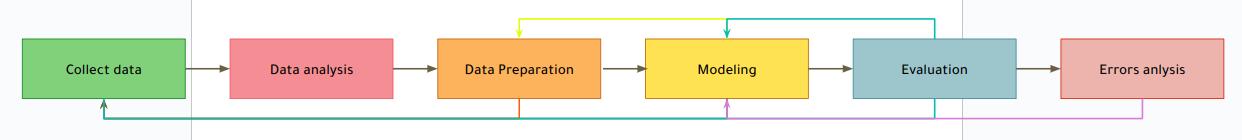

This is the usual path of a machine-learning project. **We will walk along it for text**:

1. **Collect data**: we are given a labeled dataset.
2. **Data analysis**: look at the data before touching it.
3. **Data preparation**: clean the text and turn it into numbers.
4. **Modeling**: train a classifier.
5. **Evaluation**: measure how good it is on data it has never seen.
6. **Error analysis**: look at the mistakes, then go back and improve (the arrows going backwards).

You will go around this loop several times in this notebook. That is normal: **improving a model is an experiment cycle**.

## Supervised Classification
What is Classification in general?
- Classification is the task of choosing the correct class label for a given input.

Text Classification:

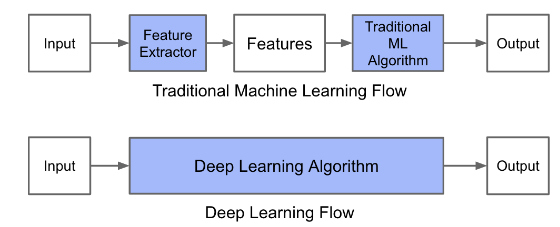

- Text classification is a way to categorize *documents* or *pieces of text*. By examining the word usage in a piece of text, classifiers can decide what **class label** to assign to it.


## Applications
- Spam	filtering
- Topic	detection
- Language	detection
- Sentiment Analysis
- ...

**Two more words you will meet often**

- **Binary classification**: exactly 2 possible labels (spam / not spam).
- **Multi-class classification**: 3 or more labels (sports / politics / tech / ...).

**Supervised** means we learn from examples that already have the correct label. A tiny example:

| Input text | Label (class) |
|---|---|
| "Forest fire near the town, residents evacuated" | disaster |
| "This new song is fire 🔥" | not a disaster |

The classifier's job: **given only the text, predict the label.**

> ### 🤔 Think
> The second tweet above uses the word *fire* but is **not** about a disaster. What makes this task harder than just 'search for disaster words'? Write one sentence.

My Answer: The context, same word can have different meaning depending on the context 

✅ Check Your Answer

<details>
<summary>Click to reveal the answers and explanations <i>(try the questions first!)</i></summary>
Words are ambiguous. Fire, bomb and explosion show up in disaster tweets and in jokes, music and slang. A keyword search can’t separate them, so the classifier has to use the surrounding words (the context).
</details>

## Our Problem

### Our Dataset: Disasters on social media
Contributors looked at over 10,000 tweets retrieved with a variety of searches like “ablaze”, “quarantine”, and “pandemonium”, then noted whether the tweet referred to a disaster event (as opposed to a joke with the word or a movie review or something non-disastrous).

**Our task (binary classification):** given a tweet, predict `1` = *about a real disaster* or `0` = *not about a disaster*.

Check that the file is where Python expects it:

In [3]:
import os

DATA_PATH = "socialmedia_disaster.csv"
if os.path.exists(DATA_PATH):
    print("✅ Found", DATA_PATH)
else:
    print("⚠️ File not found. Upload", DATA_PATH, "next to this notebook (Colab: 📁 Files panel), then re-run this cell.")

✅ Found socialmedia_disaster.csv


> ### 🎯 Predict
> The next cell loads the CSV and shows 20 rows. How many columns will you see, and what do you think each contains?
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

In [4]:
data = pd.read_csv("socialmedia_disaster.csv")
data.head(20)

,text,label
0,Just happened a terrible car crash,1
1,Our Deeds are the Reason of this #earthquake M...,1
2,"Heard about #earthquake is different cities, s...",1
3,"there is a forest fire at spot pond, geese are...",1
4,Forest fire near La Ronge Sask. Canada,1
5,All residents asked to 'shelter in place' are ...,1
6,"13,000 people receive #wildfires evacuation or...",1
7,Just got sent this photo from Ruby #Alaska as ...,1
8,#RockyFire Update => California Hwy. 20 closed...,1
9,Apocalypse lighting. #Spokane #wildfires,1


> ### 👀 Observe
> Look at the 20 rows. Is `label = 1` always obviously a disaster? Find one tweet whose label surprises you.

In [5]:
print("Rows, columns:", data.shape)
data['label'].value_counts()

Rows, columns: (9346, 2)


label
1    4673
0    4673
Name: count, dtype: int64

## 📝 Quick Check — Section 1



*Try every question on paper or in a Markdown cell **before** opening the answers.*

**Q1 (multiple choice).** Which of these is a *text classification* task?
- A. Translating an English sentence into French
- B. Deciding whether an e-mail is spam or not spam
- C. Writing a short summary of a news article
- D. Converting a voice recording into text

**Q2 (true/false + justify).** *"In our dataset, `label` is the input that the classifier receives and `text` is what it must predict."* True or false? Explain in one sentence.

**Q3 (choose the right technique).** For each task say **binary** or **multi-class**: 

(a) deciding whether a movie review is positive or negative;

(b) assigning a news article to *Sports*, *Politics*, *Health* or *Technology*.

A1 : B

A2 : False

A3 : a binary - b multiclass 

## ✅ Check Your Answers — Section 1

<details>
<summary>Click to reveal the answers and explanations <i>(try the questions first!)</i></summary>

**Think (fire):** Words are ambiguous. The same word (*fire*, *explosion*, *bomb*) appears in disaster tweets *and* in jokes, music and everyday slang, so the classifier must use the **context** (the other words), not a single keyword.

**Q1: B.** Classification means choosing a label from a fixed set of classes. A and C *produce new text*, and D converts speech to text; none of them picks a label from a fixed list.

**Q2: False.** The **text** is the input; the **label** is the target we want to predict (we only know it for training examples).

**Q3:** (a) binary (2 classes); (b) multi-class (4 classes).

</details>

---
# 2. Our Data: Split First, Then Explore

### 1.Data Analysis

before any step taken towards understanding your data, split it (if not)-into training and testing sets (at least) to avoid **data leakage**. <br><br>
Data leakage is when information from outside the training dataset is used to create the model, it usually leads to overly optimistic outcomes during the model building phase, followed by the unpleasant surprise of poor results after the prediction model is implemented and tested on new data.

**Analogy:** the test set is the *final exam*. If you see the exam questions while studying, a high score tells you nothing about what you really learned. So we lock the test set away **before** doing anything else (looking at word counts, building vocabularies, ...).

The next cell does the split. Parameters:

- `X`, `y`: the inputs (texts) and the labels, as Python lists.
- `test_size=0.2`: **20%** of the data goes to the test set, 80% to training.
- `random_state=40`: fixes the random shuffling so *everyone gets the same split* (reproducibility).

In [6]:
X = data["text"].tolist()
y = data["label"].tolist()

X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=40)

> ### 🎯 Predict
> The dataset has about 9,300 tweets. Roughly how many will be in `X_train` and `X_test`? (Hint: 80% / 20%.)
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

In [7]:
len(X_train)

7476

In [8]:
len(X_test)

1870

> ### ✏️ Modify
> Change `test_size` to `0.3` and see how the sizes change. (We use new variable names so your real split above stays untouched.)
>
> *Edit the **code cell below**, run it, and observe what changes.*

In [9]:
tmp_train, tmp_test = train_test_split(X, test_size=0.3, random_state=40)
print(len(tmp_train), len(tmp_test))

6542 2804


> ### 👀 Observe
> Look at the first two training tweets and their labels. Notice the raw text: links, mentions (`@...`), hashtags (`#...`). We will have to deal with these later.

In [10]:
X_train[:2]

['Angry Orchard Hard Cider Recalled Due To Threat of Exploding Bottles http://t.co/OXgefsoF2B',
 '@guardian Has Japan ever truly come to terms with devastation and mass murder of millions of Chinese and others with traditional weapons?']

In [11]:
y_train[:2]

[1, 1]

We convert our dataset lists to dataframe to use pandas functions that make it easier for us to work on the data.

In [12]:
train_df = pd.DataFrame({'text': X_train, 'label':y_train})
train_df.head()

,text,label
0,Angry Orchard Hard Cider Recalled Due To Threa...,1
1,@guardian Has Japan ever truly come to terms w...,1
2,Plains All American Pipeline company may have ...,1
3,People are finally panicking about cable TV ht...,0
4,The far right racist #AvigdorLiberman calls fo...,1


In [13]:
test_df = pd.DataFrame({'text': X_test, 'label':y_test})

The goal of **data analysis** is discovering useful information by informing conclusions and supporting decision making (gain an insight on our data).

### 2.1 Class balance

Do we have as many disaster tweets as non-disaster ones? This matters because it tells us what a "lazy" classifier would score. `sns.countplot` simply draws one bar per label value.

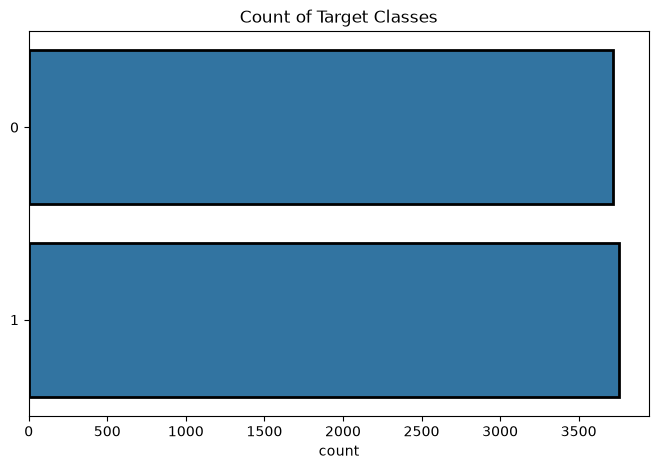

In [14]:
# Visualizing the target classes
plt.figure(figsize=(8,5))
plt.title("Count of Target Classes")
sns.countplot(y=y_train, linewidth=2,
                   edgecolor='black')

plt.show()

In [15]:
counts = pd.Series(y_train).value_counts(normalize=True)
print(counts.round(3))
print("Majority-class baseline accuracy:", round(counts.max(), 3))

1    0.503
0    0.497
Name: proportion, dtype: float64
Majority-class baseline accuracy: 0.503


The **baseline accuracy** is what you would get by *always predicting the most common class*. Any useful model must beat it. Here the classes are roughly balanced, so the baseline is about 50%.

### 2.2 Text length

Do disaster tweets look different from other tweets in **length**? We use `.str.len()` (characters per tweet) and `.str.split().map(len)` (words per tweet), then draw one histogram per class.

Let's start by analysing total number of characters in text:

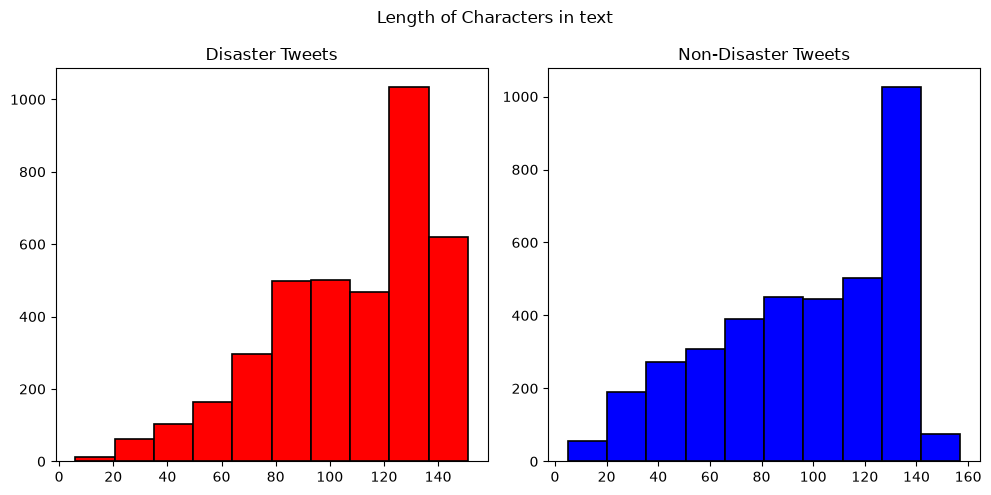

In [16]:
fig,(ax1,ax2) = plt.subplots(1, 2, figsize=(10,5))
char_len_dis = train_df[train_df['label'] == 1]['text'].str.len()
ax1.hist(char_len_dis,color='red',edgecolor='black', linewidth=1.2)
ax1.set_title('Disaster Tweets')

char_len_ndis = train_df[train_df['label'] == 0]['text'].str.len()
ax2.hist(char_len_ndis,color='blue',edgecolor='black', linewidth=1.2)
ax2.set_title('Non-Disaster Tweets')

plt.suptitle("Length of Characters in text")
plt.tight_layout()
plt.show()

In [17]:
char_len_dis

0        91
1       137
2       132
4       139
5        73
       ... 
7465    138
7467     81
7468    102
7469    139
7472    143
Name: text, Length: 3758, dtype: int64

↑ That is a pandas **Series**: one number (character count) per disaster tweet. The histogram counts how many tweets fall into each length range.

Analysing number of words in text:

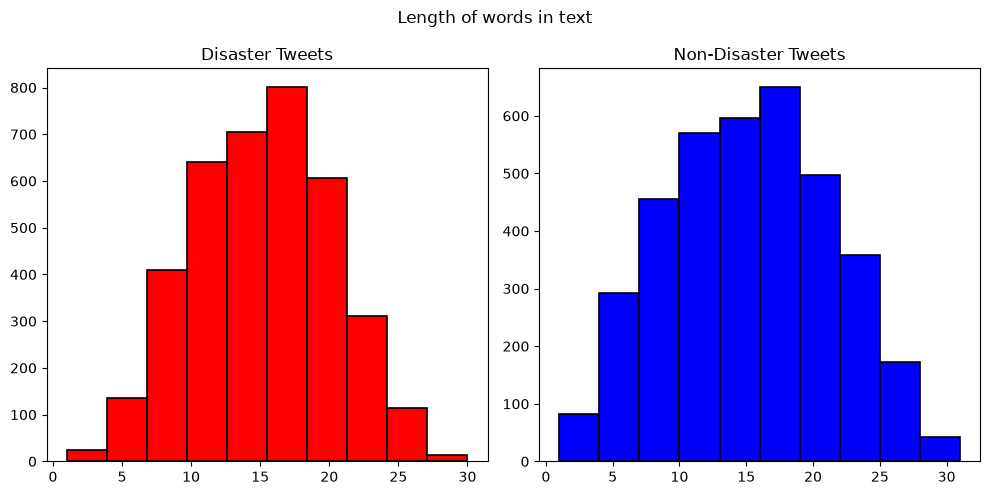

In [18]:
fig,(ax1,ax2) = plt.subplots(1,2,figsize=(10,5))
words_len_dis = train_df[train_df['label'] == 1]['text'].str.split().map(lambda x: len(x))
ax1.hist(words_len_dis,color='red',edgecolor='black', linewidth=1.2)
ax1.set_title('Disaster Tweets')

words_len_ndis = train_df[train_df['label'] == 0]['text'].str.split().map(lambda x: len(x))
ax2.hist(words_len_ndis,color='blue',edgecolor='black', linewidth=1.2)
ax2.set_title('Non-Disaster Tweets')

plt.suptitle("Length of words in text")
plt.tight_layout()
plt.show()

> ### 🤔 Think
> Compare the red and blue histograms (both for characters and for words). Would *length alone* be a good feature to tell the classes apart? Why or why not?
>


No , the distrubutions are similiar

✅ Check Your Answers

<details>
<summary>Click to reveal the answers and explanations <i>(try the questions first!)</i></summary>

No. The red and blue histograms overlap almost completely, and both classes are mostly 60–140 characters. Length alone is a weak feature.
</details>

### 2.3 Word frequencies and word clouds

**Frequency Analyses**<br><br>
To visualize text data, generally, we use the `wordcloud` but there are some other techniques also, which we can try to visualize the data such as  `Frequency Distribution`

Word Cloud is a data visualization technique in which words from a given text display on the main chart. Some properties associated with this chart are as follows:

- In this technique, more frequent or essential words display in a larger and bolder font,
- While less frequent or essential words display in smaller or thinner fonts.
This data visualization technique gives us a glance at what text should be analyzed, so it is a very beneficial technique in NLP tasks.

**Advantages of Word Cloud**<br>
- They are fast.
- They are engaging.
- They are simple to understand.
- They are casual and visually appealing.

**Disadvantages of Word Cloud**<br>
- They are non-perfect for non-clean data.
- They lack the context of words.


Here, to draw the word cloud, we use the following text:

> ### 🗣️ Explain
> Without running anything: in your own words, how does a word cloud decide which words to draw big?
>
> *Write 2–3 sentences in this cell: double-click, type below the line, then press Shift+Enter.*

✍️ **Your explanation:** *(double-click to edit)*

By counting each word frequency using a map data structure or anything similiar

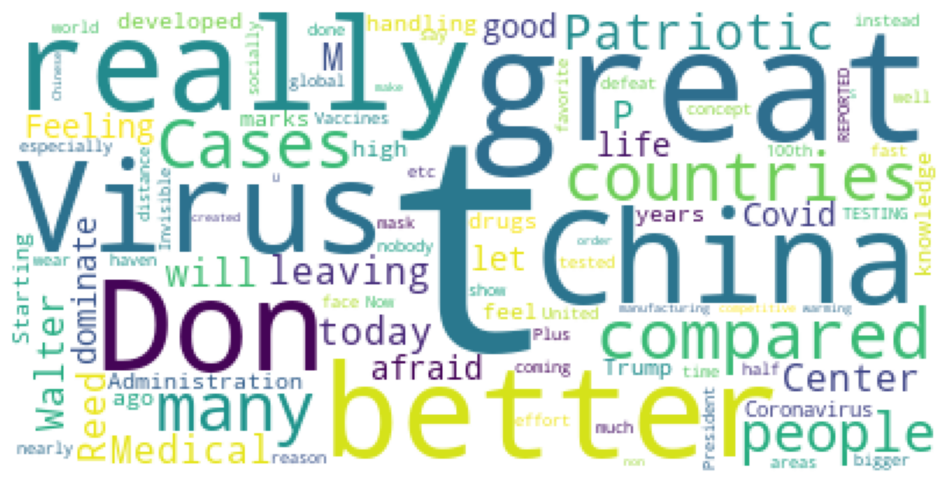

In [19]:
text = "I will be leaving the great Walter Reed Medical Center today at 6:30 P.M. Feeling really good! Don’t be afraid of Covid. Don’t let it dominate your life. We have developed, under the Trump Administration, some really great drugs & knowledge. I feel better than I did 20 years ago! Starting to get VERY high marks in our handling of the Coronavirus (China Virus), especially when compared to other countries and areas of the world. Now the Vaccines (Plus) are coming, and fast! For the 1/100th time, the reason we show so many Cases, compared to other countries that haven’t done nearly as well as we have, is that our TESTING is much bigger and better. We have tested 40,000,000 people. If we did 20,000,000 instead, Cases would be half, etc. NOT REPORTED! We are United in our effort to defeat the Invisible China Virus, and many people say that it is Patriotic to wear a face mask when you can’t socially distance. There is nobody more Patriotic than me, your favorite President! The concept of global warming was created by and for the Chinese in order to make U.S. manufacturing non-competitive."

wordcloud = WordCloud(background_color ='white',).generate(text)
plt.figure(figsize = (12,12))
plt.imshow(wordcloud)

plt.axis("off")
plt.show()

In [20]:
wordcloud.words_

{'t': 1.0,
 'great': 0.5,
 'really': 0.5,
 'Don': 0.5,
 'better': 0.5,
 'China': 0.5,
 'Virus': 0.5,
 'compared': 0.5,
 'countries': 0.5,
 'many': 0.5,
 'Cases': 0.5,
 'people': 0.5,
 'Patriotic': 0.5,
 'will': 0.25,
 'leaving': 0.25,
 'Walter': 0.25,
 'Reed': 0.25,
 'Medical': 0.25,
 'Center': 0.25,
 'today': 0.25,
 'P': 0.25,
 'M': 0.25,
 'Feeling': 0.25,
 'good': 0.25,
 'afraid': 0.25,
 'Covid': 0.25,
 'let': 0.25,
 'dominate': 0.25,
 'life': 0.25,
 'developed': 0.25,
 'Trump': 0.25,
 'Administration': 0.25,
 'drugs': 0.25,
 'knowledge': 0.25,
 'feel': 0.25,
 'years': 0.25,
 'ago': 0.25,
 'Starting': 0.25,
 'high': 0.25,
 'marks': 0.25,
 'handling': 0.25,
 'Coronavirus': 0.25,
 'especially': 0.25,
 'areas': 0.25,
 'world': 0.25,
 'Now': 0.25,
 'Vaccines': 0.25,
 'Plus': 0.25,
 'coming': 0.25,
 'fast': 0.25,
 '100th': 0.25,
 'time': 0.25,
 'reason': 0.25,
 'show': 0.25,
 'haven': 0.25,
 'done': 0.25,
 'nearly': 0.25,
 'well': 0.25,
 'TESTING': 0.25,
 'much': 0.25,
 'bigger': 0.25,
 '

> ### 👀 Observe
> The word `t` has the highest score (1.0). Where does a lone `t` come from? *(Hint: look at `Don’t` in the text.)* What does this tell you about the tokenizer that `WordCloud` uses internally?

Now we build one word cloud **per class** from the training data. Read the first two lines as: *"take all tweets with label 1, put them in a list, glue them into one big string with spaces"*.

In [21]:
class1_text = " ".join(train_df[train_df['label'] == 1]['text'].tolist())
class2_text = " ".join(train_df[train_df['label'] == 0]['text'].tolist())

disaster_cloud = WordCloud(width = 1000, height = 800,
                background_color ='white',
                min_font_size = 10).generate(class1_text)

non_disaster_cloud = WordCloud(width = 1000, height = 800,
                background_color ='white',
                min_font_size = 10).generate(class2_text)

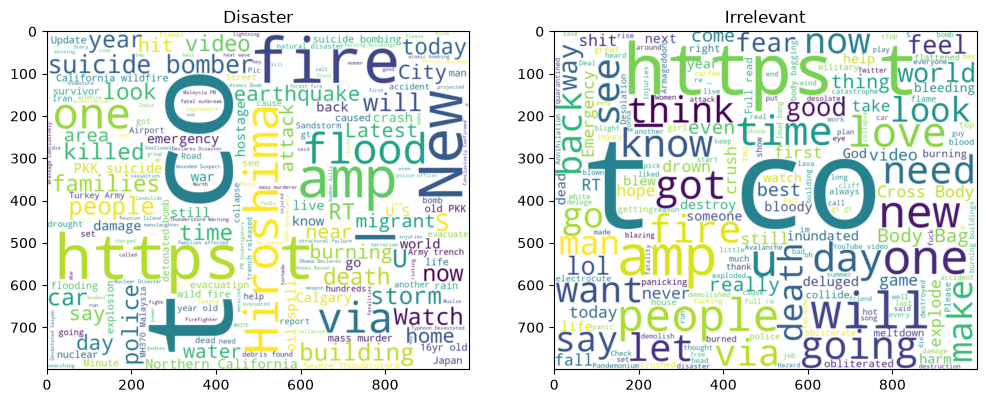

In [22]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 6))
axes[0].imshow(disaster_cloud, interpolation="bilinear")
axes[0].title.set_text('Disaster')

axes[1].imshow(non_disaster_cloud, interpolation="bilinear")
axes[1].title.set_text('Irrelevant')

> ### 👀 Observe
> Compare the two clouds. Which words look **informative** (e.g. they clearly point to a disaster)? Which look like **noise** (links, `co`, `http`, `amp`)? Keep the noise list in mind. It motivates the cleaning we do in Section 3.

## 📝 Quick Check — Section 2



*Try every question on paper or in a Markdown cell **before** opening the answers.*

**Q1 (multiple choice).** What is *data leakage*?
- A. Losing some rows of the dataset by accident
- B. Information from the test data influencing the training of the model
- C. Training a model for too many epochs
- D. Having more words in the vocabulary than tweets

**Q2 (true/false + justify).** *"It is fine to count word frequencies on the **whole** dataset before splitting, as long as we never look at the labels."* True or false?

**Q3 (code tracing).** You have 400 tweets and run `train_test_split(X, y, test_size=0.25, random_state=1)`. How many tweets are in the training set? What is `random_state` for?

**Q4 (choose the technique).** You want a quick visual overview of which words are most frequent in one class. Which tool from this section fits best: *histogram of lengths*, *count plot*, or *word cloud*?

A1 : B

A2 : False , in this way we know that i will see these words in the future, which is not true in real life scinearioes, I will face words that does not exist in the dataset

A3 : 300 tweets in training set, random state is like a seed for the random algorithm , by providing the same seed , we will garuntee that same shuffle of the data would happen in every run (imagining training data are lecutres  and test data is the exam , like this we keep the lectures and the exam are the same in every run , so we can see our performance and compare it)

A4 : word cloud, historgram of lenghts is not useful, count plot can be useful if the number of words is small, but in case we have long texts with varity in words , word clouds are better since we can see them visually

## ✅ Check Your Answers — Section 2

<details>
<summary>Click to reveal the answers and explanations <i>(try the questions first!)</i></summary>

**Think (length):** Usually the two histograms overlap heavily: tweets in both classes are mostly 60–140 characters long. Length alone is a **weak** feature. Both classes use the same range, so it cannot separate them reliably.

**Explain (word cloud):** The cloud counts how often each word appears; frequent words get a larger, bolder font and rare words a smaller one.

**Observe (`t`):** `Don’t` was split at the apostrophe (`’`) into `Don` and `t`. The default word-cloud tokenizer treats the apostrophe as a separator. Tokenizing is full of such details, which is the topic of Section 3.

**Observe (noise):** Typical noise: `http`, `co` (from `t.co` links), `amp` (from `&amp;`), very common words (*the*, *to*).

**Q1: B.** Leakage means information from outside the training set (e.g. the test set) is used while building the model. It makes results look better than they will be in real life.

**Q2: False.** Even without labels, the *test texts* would influence the vocabulary or statistics we compute, so test information leaks into training. Always split first.

**Q3: 300 tweets.** (400 × 0.75 = 300; the other 100 go to the test set.) `random_state` fixes the random shuffle so the split is **reproducible**.

**Q4: word cloud.** Histograms and count plots show lengths/class sizes, not individual words.

</details>

---
# 3. Preparing Raw Text

## 3.0 Why preprocess at all?

`Preprocessing` is the step that transforms and cleans raw text so that it becomes easy to understand and efficient to work with.

These techniques reduce the complexity of the language data and often improve speed and accuracy. But **apply them judiciously**: every step *removes* information, and whether that information is useful depends on your task. In this notebook we will **measure** the effect of each step instead of guessing.

**What is text?**
You can think of text as a sequence of
- Characters
- **Words**
- Phrases and named entities
- Sentences
- Paragraphs
- ...

**What is a word?**<br>
- A word is a meaningful sequence of characters<br>
**How to find the boundaries of words?**<br>
- In *English* we can split a sentence by spaces or punctuation
    - Friends, Romans, Countrymen, lendme your ears;
    - Output:[Friends, Romans, Countrymen, lend, me, your, ears]
- In *German* there are compound words which are written without spaces
    - “Rechtsschutzversicherungsgesellschaften” stands for “insurance companies which provide legal protection”
- In *Japanese* there are no spaces at all!
    - Butyoucanstillreaditright?
- In *Arabic*?

> ### 🤔 Think
> The last bullet above asks: *how are words separated in **Arabic**?* Do you think splitting on spaces is enough? Think of how prefixes such as *و* (and), *ب* (with/in) or *ال* (the) are written.
>
✅ Check Your Answers

<details>
<summary>Click to reveal the answers and explanations</summary>

Spaces aren’t enough. Arabic attaches prefixes and suffixes to the word (e.g. وبالكتاب = and + with + the + book). Splitting on spaces leaves these glued together, so Arabic needs a morphological segmenter on top.
</details>

My Answer : we can split by spaces , each word can have a prefix and a suffix maybe

**Key idea to remember:** *what counts as a word depends on the task.* Should punctuation count? Should `They` and `they` be the same word? Should `uh`/`um` be kept? For example, *"He stepped out into the hall, was delighted to encounter a water brother."* has **13 words** without punctuation and **15** if we count the comma and full stop as tokens.

<details>
<summary>📖 <b>Read at Home:</b> what is a word? (longer examples) <i>(optional, click to expand)</i></summary>

Let's take some examples:

How many words are in the following sentence?

- <font color='skyblue'>He stepped out into the hall, was delighted to encounter a water brother.</font>

  This sentence has <font color='orangered'>13 words</font> if we don’t count punctuation marks as words, <font color='orangered'>15</font> if we count punctuation.
  
  Whether we treat period (“.”), comma (“,”), and so on as words `depends on the task`. Punctuation is critical for finding boundaries of things (commas, periods, colons) and for identifying some aspects of meaning (question marks, exclamation marks, quotation marks). For some tasks, like part-of-speech tagging or parsing or speech synthesis, we sometimes treat punctuation marks as if they were separate words.

- <font color='skyblue'>I do uh main- mainly business data processing</font>

  This utterance has two kinds of <font color='lightgreen'>disfluencies</font>. The broken-off word main- is called a <font color='lightgreen'>fragment</font>. Words like uh and um are called <font color='lightgreen'>fillers or filled pauses</font>. `Should we consider these to be words? `Again, it depends on the application. If we are building a speech transcription system, we might want to eventually strip out the disfluencies. But we also sometimes keep disfluencies around. Disfluencies like uh or um are actually helpful in speech recognition in predicting the upcoming word, because they may signal that the speaker is restarting the clause or idea, and so for speech recognition they are treated as regular words.

- <font color='skyblue'>They picnicked by the pool, then lay back on the grass and looked at the stars.</font>

  `Should we consider a capitalized string (like They) and one that is uncapitalized (like they) to be the same word type?` The answer is that it depends on the task! They and they might be lumped together as the same type in some tasks, like speech recognition, where we care more about the sequence of words and less about the formatting, while for other tasks, such as deciding whether a particular word is a name of a person or location (named entity tagging), capitalization is a useful feature and is retained.

- It’s also quite common for speakers or writers to use multiple languages in a single communicative act, a phenomenon called <font color='lightgreen'>code switching</font>.

</details>

## 3.1 Tokenization

#### Tokenization
Tokenization is a process that *splits* an input sequence into so-called **tokens**.
- You can think of a token as a **useful unit** for semantic processing.
- Can be a word, sentence, paragraph, etc.
- Ideally you could turn tokens back into text (*detokenization*), but most tokenizers are **not perfectly lossless**: e.g. the exact whitespace and line breaks are usually lost.
- NLTK includes some off-the-shelf tokenizers:

We will compare tokenizers on the same sentence. For each one: **predict first, then run**.

In [23]:
text = "This is Andrew’s text, isn’t it?"

**Whitespace tokenizer**: cuts the text at spaces/tabs/newlines. Nothing else.

> ### 🎯 Predict
> How many tokens will the whitespace tokenizer give for `This is Andrew’s text, isn’t it?` Will the comma stay attached to `text`?
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

In [24]:
tokenizer = nltk.tokenize.WhitespaceTokenizer()
tokens = tokenizer.tokenize(text)
print(tokens)

['This', 'is', 'Andrew’s', 'text,', 'isn’t', 'it?']


**Word-punctuation tokenizer**: separates runs of letters/digits from runs of punctuation.

In [25]:
tokenizer = nltk.tokenize.WordPunctTokenizer()
tokens = tokenizer.tokenize(text)
print(tokens)

['This', 'is', 'Andrew', '’', 's', 'text', ',', 'isn', '’', 't', 'it', '?']


> ### 👀 Observe
> Compare the two outputs. What happened to `Andrew’s` and `isn’t`? Which output would you prefer for a classifier, and why?

**Regular-expression tokenizer**: *you* write the rules. The pattern `\w+|\$[\d\.]+|\S+` reads as three alternatives, tried in this order:

- `\w+`: a run of letters, digits or `_` (a normal word);
- `\$[\d\.]+`: a `$` followed by digits and dots (a price like `$3.88`);
- `\S+`: any other chunk of non-space characters (punctuation, symbols).

In [26]:
s = "Good muffins cost $3.88\nin New York.  Please buy me\ntwo of them.\n\nThanks."
tokenizer = RegexpTokenizer(r'\w+|\$[\d\.]+|\S+')
print(tokenizer.tokenize(s))

['Good', 'muffins', 'cost', '$3.88', 'in', 'New', 'York', '.', 'Please', 'buy', 'me', 'two', 'of', 'them', '.', 'Thanks', '.']


*(Changed from the original: the pattern is now a **raw string** `r'...'`. Without the `r`, Python warns about the backslashes.)*

This may go wrong in many ways...

> ### ✏️ Modify
> Delete the last alternative `|\S+` from the pattern (so it becomes `r'\w+|\$[\d\.]+'`) and run the cell below. What happens to the full stops? What does that tell you about the last alternative?
>
> *Edit the **code cell below**, run it, and observe what changes.*

My Note : dots was removed

In [27]:
s = "Good muffins cost $3.88\nin New York.  Please buy me\ntwo of them.\n\nThanks."
tokenizer = RegexpTokenizer(r'\w+|\$[\d\.]+')     # <-- edit this pattern
print(tokenizer.tokenize(s))

['Good', 'muffins', 'cost', '$3.88', 'in', 'New', 'York', 'Please', 'buy', 'me', 'two', 'of', 'them', 'Thanks']


**Treebank word tokenizer**: the standard from the Penn Treebank corpus.

> ### 🎯 Predict
> Where will the Treebank tokenizer cut `$3.88`, and what will it do with the full stop in `York.` in the middle of the text versus the final `Thanks.`?
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

In [28]:
text = "Good muffins cost $3.88\nin New York. Please buy me\ntwo of them.\n\nThanks."
print(text + "\n______________")
tokenizer = TreebankWordTokenizer()
print(tokenizer.tokenize(text))

Good muffins cost $3.88
in New York. Please buy me
two of them.

Thanks.
______________
['Good', 'muffins', 'cost', '$', '3.88', 'in', 'New', 'York.', 'Please', 'buy', 'me', 'two', 'of', 'them.', 'Thanks', '.']


What about the dots at the sentences ends?!

The Treebank tokenizer uses regular expressions to tokenize text as in Penn Treebank.

This tokenizer performs the following steps:

- split standard contractions, e.g. don't -> do n't and they'll -> they 'll.

- treat most punctuation characters as separate tokens.

- split off commas and single quotes, when followed by whitespace.

- separate periods that appear at the end of line.

*Note that word_tokenize works only at the sentence level. So you'll have to split at the sentence level and the tokenize the sentences.*

In [29]:
text = "Good muffins cost $3.88\nin New York. Please buy me\ntwo of them.\n\nThanks."
tokenizer = TreebankWordTokenizer()
sents = nltk.sent_tokenize(text)
print(sents)
print(tokenizer.tokenize_sents(sents))

['Good muffins cost $3.88\nin New York.', 'Please buy me\ntwo of them.', 'Thanks.']
[['Good', 'muffins', 'cost', '$', '3.88', 'in', 'New', 'York', '.'], ['Please', 'buy', 'me', 'two', 'of', 'them', '.'], ['Thanks', '.']]


The most use-sentence segmentation fulcues for segmenting a text into sentences are punctuation, like periods, question marks, and exclamation points. Question marks and exclamation points are relatively unambiguous markers of sentence boundaries. Periods, on the other hand, are more ambiguous. The period character “.” is ambiguous between a sentence boundary marker and a marker of <font color='orangered'>abbreviations like Mr. or Inc.</font> The previous sentence that you just read showed an even more complex case of this ambiguity, in which the final period of Inc. marked both an abbreviation and the sentence boundary marker. For this reason, sentence tokenization and word tokenization may be addressed jointly.

Some drawbacks to the Treebank style:

- Contractions like (isn't) should be splited into 2 tokens.
- Almost all tokens that involve punctuation are split apart — URLs, Twitter mark-up, phone numbers, dates, email addresses ... Thus, emoticons are collapsed with their component parts, URLs are not constituents, and Twitter mark-up is lost.

**Tweet tokenizer**: designed for social media. It keeps hashtags, mentions, URLs and emoticons intact.

In [30]:
tweet = data.iloc[83]['text']
print(tweet)
tokenizer = TweetTokenizer()
print(tokenizer.tokenize(tweet))

Experts in France begin examining airplane debris found on Reunion Island: French air accident experts on... http://t.co/TagZbcXFj0 #MLB
['Experts', 'in', 'France', 'begin', 'examining', 'airplane', 'debris', 'found', 'on', 'Reunion', 'Island', ':', 'French', 'air', 'accident', 'experts', 'on', '...', 'http://t.co/TagZbcXFj0', '#MLB']


> ### 🐞 Debug
> Someone tried to tokenize a tweet but got an error. Run the next cell and read the message.
>
> *The next cell runs but shows a problem. Read the message/output, then fix it in the cell after it.*

In [31]:
try:
    tokens = TweetTokenizer.tokenize("Flood warning in #Houston!")
except TypeError as error:
    print("Error:", error)

Error: TweetTokenizer.tokenize() missing 1 required positional argument: 'text'


**Fix it** in this cell (hint: a tokenizer is a *class*. You must create an *object* from it first):

In [32]:
# your fixed code here
tokenizer  = TweetTokenizer()
tokens = tokenizer.tokenize("Flood warning in #Houston!")
tokens

['Flood', 'warning', 'in', '#Houston', '!']

The tokenization choice obviously depends on your task, for example if your task is sentiment analysis, you should think of a tokenizer achive:

- Isolates emoticons
- Respects Twitter and other domain-specific markup
- Uses the underlying mark-up (e.g., \<strong\> tags)
- Captures those #$%ing masked curses!
- Preserves capitalization where it seems meaningful
- Regularizes lengthening (e.g., YAAAAAAY⇒YAAAY)
- Captures significant multiword expressions (e.g., out of
this world)

for Example:

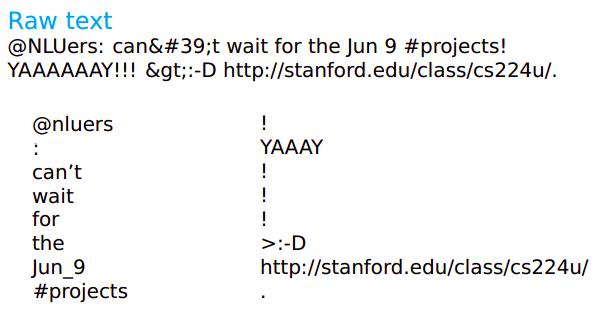

**Detokenizing**: joining tokens back into a string. Note that we store the result in a **new** variable (`detokenized`). The original notebook overwrote `tweet`, so re-running the cell fed already-processed text back in.

In [33]:
tweet = data.iloc[83]['text']
tokenizer = TreebankWordTokenizer()
detokenizer = TreebankWordDetokenizer()

print(f'Original Tweet: {tweet}')

tokens = tokenizer.tokenize(tweet)
print(f'Tweet Tokens: {tokens}')

detokenized = detokenizer.detokenize(tokens)
print(f'Detokenized tweet: {detokenized}')

Original Tweet: Experts in France begin examining airplane debris found on Reunion Island: French air accident experts on... http://t.co/TagZbcXFj0 #MLB
Tweet Tokens: ['Experts', 'in', 'France', 'begin', 'examining', 'airplane', 'debris', 'found', 'on', 'Reunion', 'Island', ':', 'French', 'air', 'accident', 'experts', 'on', '...', 'http', ':', '//t.co/TagZbcXFj0', '#', 'MLB']
Detokenized tweet: Experts in France begin examining airplane debris found on Reunion Island: French air accident experts on...http: //t.co/TagZbcXFj0 #MLB


> ### 👀 Observe
> Is the detokenized tweet identical to the original? Look at the URL. This is what 'not perfectly lossless' means.

### 🧩 Practice: tokenize and normalize with regular expressions

**Practice exercise**:

Try to tokenize and normalize the input text to get the expected output by regular expression:<br>

**input text**: I was walking towards my house evening, and suddenly a black-coat man appeared in front of me !!!I was scared sooooo much . .. but it turned out that he was just a homeless , I gave him 5.5$ and made my way home.

**expected output**: i was walking towards my house evening , and suddenly a black-coat man appeared in front of me ! i was scared so much ... but it turned out that he was just a homeless , i gave him 5.5 $ and made my way home .

<details>
<summary>💡 <b>Hints</b> (open one at a time, only if you are stuck)</summary>

1. Start with `text.lower()`. The expected output is all lowercase.
2. Several steps can be done with `re.sub(pattern, replacement, text)`: collapse `!!!` into `!`; join `. ..` into `...`; shrink letters repeated 3+ times (`sooooo` → `so`) with `([a-z])\1{2,}` and the replacement `\1`.
3. For the final split, `RegexpTokenizer` with **ordered alternatives** works well: first decimal numbers like `5.5`, then words that may contain hyphens like `black-coat`, then `...`, then any single punctuation character.
4. Finally, `" ".join(tokens)` puts spaces between tokens.

</details>

In [34]:
exercise_text = "I was walking towards my house evening, and suddenly a black-coat man appeared in front of me !!!I was scared sooooo much . .. but it turned out that he was just a homeless , I gave him 5.5$ and made my way home."

expected = "i was walking towards my house evening , and suddenly a black-coat man appeared in front of me ! i was scared so much ... but it turned out that he was just a homeless , i gave him 5.5 $ and made my way home ."

# 1. Convert the entire string to lowercase
text = exercise_text.lower()

# 2. Collapse multiple exclamation marks into a single '!' with surrounding spaces
text = re.sub(re.compile(r'\s*!+\s*'), ' ! ', text)


# 4. Standardize punctuation like commas (space only after)
text = re.sub(re.compile(r'\s*,\s*'), ' , ', text)
text = re.sub(re.compile(r'\s*\.\s*'), ' . ', text)

# 5. Reduce 3+ repeating characters (like 'sooooo') down to a maximum of 2 ('soo')
text = re.sub(re.compile(r'(.^\.)\1{2,}'), r'\1\1', text)
# 3. Collapse multiple dots or spaces around dots into '...' with surrounding spaces
# text = re.sub(re.compile(r'(\.\s*)\1{2,}'), ' ... ', text)
text = re.sub(r'\.\s*\.\s*\.', ' ... ', text)
text = re.sub(r'\s*\.\.\.\s*', ' ... ', text)

# # 6. Put a space before the dollar sign if attached to a number
text = re.sub(re.compile(r'(\d+)\$'), r'\1 $', text)

# 7. Clean up any accidental double spaces created during processing
text = re.sub(re.compile(r'\s+'), ' ', text).strip()
print(text)
result = text

i was walking towards my house evening , and suddenly a black-coat man appeared in front of me ! i was scared sooooo much ... but it turned out that he was just a homeless , i gave him 5 . 5 $ and made my way home .


In [35]:
# Self-check: run after you have written your solution
if result == expected:
    print("✅ Correct!")
elif result == "":
    print("⚠️ Not started yet. Write your code in the cell above.")
else:
    print("❌ Not identical yet. Compare the two strings:")
    print("yours   :", result)
    print("expected:", expected)

❌ Not identical yet. Compare the two strings:
yours   : i was walking towards my house evening , and suddenly a black-coat man appeared in front of me ! i was scared sooooo much ... but it turned out that he was just a homeless , i gave him 5 . 5 $ and made my way home .
expected: i was walking towards my house evening , and suddenly a black-coat man appeared in front of me ! i was scared so much ... but it turned out that he was just a homeless , i gave him 5.5 $ and made my way home .


## 3.2 Token normalization

#### Why normalize tokens?
- This is an optional step that may improve your classification.
- We may want the same token for different forms of the word
    - wolf, wolves -> wolf
    - talk, talks -> talk

Two common methods: **stemming** (chop endings with rules) and **lemmatization** (look the word up in a dictionary).

##### **Stemming**<br>
- A process of removing and **replacing suffixes** to get to the root form of the word, which is called the **stem**
- Usually refers to **heuristics** that chop off suffixes

In [36]:
raw = """DENNIS: Listen, strange women lying in ponds distributing swords
... is no basis for a system of government.  Supreme executive power derives from
... a mandate from the masses, not from some farcical aquatic ceremony. mice"""
tokenizer = TreebankWordTokenizer()
tokens = tokenizer.tokenize(raw)

**Porter Stemmer**<br>
- 5 heuristic phases of word reductions, applied sequentially
- Example of phase 1 rules:
    - SSES → SS <br>
        e.g. caresses → caress
    - IES→ I <br>
        e.g. ponies →poni
    - SS→ SS <br>
        e.g. caress → caress
    - S→ <br>
        e.g. cats → cat
    - ATIONAL → ATE <br>
        e.g., relational → relate
    - ING →  <br>
        e.g., motoring → motor

more at https://tartarus.org/martin/PorterStemmer/

`nltk.PorterStemmer()` creates the stemmer object. The list comprehension `[(t, porter.stem(t)) for t in tokens]` applies `.stem()` to every token and keeps the original next to its stem so you can compare.

> ### 🎯 Predict
> What stem will Porter give for `ponds`, `lying`, `Listen` and `basis`? Will they all be real English words?
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

In [37]:
porter = nltk.PorterStemmer()
[(t, porter.stem(t)) for t in tokens]

[('DENNIS', 'denni'),
 (':', ':'),
 ('Listen', 'listen'),
 (',', ','),
 ('strange', 'strang'),
 ('women', 'women'),
 ('lying', 'lie'),
 ('in', 'in'),
 ('ponds', 'pond'),
 ('distributing', 'distribut'),
 ('swords', 'sword'),
 ('...', '...'),
 ('is', 'is'),
 ('no', 'no'),
 ('basis', 'basi'),
 ('for', 'for'),
 ('a', 'a'),
 ('system', 'system'),
 ('of', 'of'),
 ('government.', 'government.'),
 ('Supreme', 'suprem'),
 ('executive', 'execut'),
 ('power', 'power'),
 ('derives', 'deriv'),
 ('from', 'from'),
 ('...', '...'),
 ('a', 'a'),
 ('mandate', 'mandat'),
 ('from', 'from'),
 ('the', 'the'),
 ('masses', 'mass'),
 (',', ','),
 ('not', 'not'),
 ('from', 'from'),
 ('some', 'some'),
 ('farcical', 'farcic'),
 ('aquatic', 'aquat'),
 ('ceremony.', 'ceremony.'),
 ('mice', 'mice')]

Problems:
- Fails on irregular forms, produces non-words.
- over-generalizating (e.g. policy to police) and under-generalizing (not stemming European to Europe).

> ### 🤔 Think
> Look at `DENNIS → denni` and `basis → basi`. These are not real words. Is that a problem if our only goal is to feed a classifier?
>
✅ Check Your Answers

<details>
<summary>Click to reveal the answers and explanations</summary>

Usually not for classification. What matters is that all forms of a word map to the same token (derive, derives, derived → deriv), so the classifier sees fewer and stronger features. The real risk is the opposite: merging words that have different meanings.
</details>

**The dangers of stemming:**<br>

Stemming can sometimes be a rudimentary method, as it merely truncates the ends of words using simplistic rules without understanding the context. This can lead to erroneous outputs where the stemmed word is not a valid word or has a different meaning.

Stemming collapses distinct word forms!!<br>

as an example:


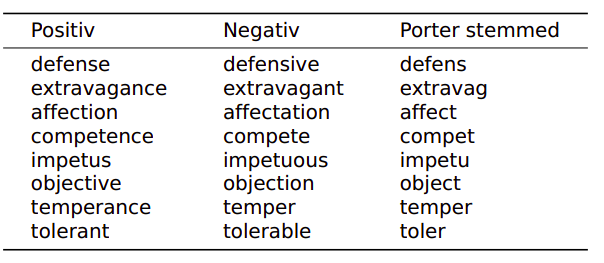

##### Lemmatization

- Usually refers to doing things properly with the use of a vocabulary and **morphological analysis**
- Returns the base or dictionary form of a word, which is known as the **lemma**
- The process involves understanding the context and part of speech of the word, making it more complex and accurate than stemming.
For example, the word “better” has “good” as its lemma. Lemmatization would correctly identify this, while stemming would not. the complexity of lemmatization can also make it computationally more expensive than stemming.

> ### 🎯 Predict
> `WordNetLemmatizer` is called without telling it the part of speech. Will it handle `women`, `mice`, `lying` and `derives`?
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

In [38]:
wnl = nltk.WordNetLemmatizer()
lemmatizedTokens =[wnl.lemmatize(t) for t in tokens]
for index, (token, lemma) in enumerate(zip(tokens, lemmatizedTokens)):
    print(token + "\t" + lemma)

DENNIS	DENNIS
:	:
Listen	Listen
,	,
strange	strange
women	woman
lying	lying
in	in
ponds	pond
distributing	distributing
swords	sword
...	...
is	is
no	no
basis	basis
for	for
a	a
system	system
of	of
government.	government.
Supreme	Supreme
executive	executive
power	power
derives	derives
from	from
...	...
a	a
mandate	mandate
from	from
the	the
masses	mass
,	,
not	not
from	from
some	some
farcical	farcical
aquatic	aquatic
ceremony.	ceremony.
mice	mouse


**Observe:** `women → woman` and `mice → mouse` work (irregular plurals, which stemming cannot do), but `lying` and `derives` are unchanged. The lemmatizer **assumes every word is a noun** unless you tell it otherwise with the `pos` argument (`'n'` noun, `'v'` verb, `'a'` adjective).

> ### ✏️ Modify
> Change `pos='v'` to other values (`'n'`, `'a'`) and the word to others (e.g. `'running'`, `'better'`) to see how the part of speech changes the lemma.
>
> *Edit the **code cell below**, run it, and observe what changes.*

In [39]:
print(wnl.lemmatize("running", pos="n"), wnl.lemmatize("derives", pos="v"), wnl.lemmatize("better", pos="n"))

running derive better


<details>
<summary>📖 <b>Read at Home:</b> Lancaster stemmer (a more aggressive stemmer) <i>(optional, click to expand)</i></summary>

Like the Porter stemmer, the **Lancaster** stemmer is a set of rules where each rule deletes or replaces an ending. It applies rules **iteratively** and is more aggressive: it often cuts words much shorter. Compare its output with Porter's above.

</details>

In [40]:
lancaster = nltk.LancasterStemmer()
[(t, lancaster.stem(t)) for t in tokens][:12]

[('DENNIS', 'den'),
 (':', ':'),
 ('Listen', 'list'),
 (',', ','),
 ('strange', 'strange'),
 ('women', 'wom'),
 ('lying', 'lying'),
 ('in', 'in'),
 ('ponds', 'pond'),
 ('distributing', 'distribut'),
 ('swords', 'sword'),
 ('...', '...')]

## 3.3 Cleaning our tweets

#### More normalization ideas

Convert to lowercase.
Remove punctuation from each token.
Filter out remaining tokens that are not alphabetic.

1. Normalizing capital letters<br>
  Usually we simply lowercase each letter
  but it is not always perfect because:
  - Us, us -> us(if both are pronoun)
  - us, US (could be pronoun and country)
  - We can use heuristics:
      −lowercasing the beginning of the sentence
      −lowercasing words in titles
      −leave mid-sentence words as they are
    - Or we can use machine learning to retrieve true casing -> hard
     
     
2. Noise Entities Removal<br>
  Noise is considered as that piece of text which is not relevant to the context of the data and the final output.
  For Example,
  - URLs or links,
  - Social media entities (mentions, hashtags),
  - Punctuations, and Industry-Specific words.

3. Filter out remaining tokens that are not alphabetic.<br>
  Non-alphanumeric characters include any characters that are not letters or digits, like ">" and "?".

4. Spell Check and Correction:
Typos and spelling mistakes are common in text data. Spell check and correction can be used to correct these errors. This step can help in reducing multiple copies of words. For example, “speling” and “spelling” will be considered as two different words unless corrected.

5. Converting numbers to their word equivalents?
    

`How to know which cleaning operation is suitable for our task?`

**Answer:** you can't know in advance. You **try the step, retrain, and compare the test accuracy**. That is exactly what Sections 4–6 do.

Now lets clean and standardize our data:

**Remove empty rows and duplicates.** `dropna()` drops rows with missing values; `drop_duplicates()` drops repeated rows. `.shape` prints *(rows, columns)* so we can see how many rows disappeared.

In [41]:
# remove empty rows
train_df = train_df.dropna()
train_df = train_df.drop_duplicates()
train_df.shape

(7368, 2)

In [42]:
test_df = test_df.dropna()
test_df = test_df.drop_duplicates()
test_df.shape

(1852, 2)

> ### 🤔 Think
> We removed duplicates *inside* the train set and *inside* the test set separately. Could the same tweet still appear in **both**? Would that be a problem for evaluation? (Many tweets are retweets.)
>
✅ Check Your Answers

<details>
<summary>Click to reveal the answers and explanations</summary>

Yes, the same tweet (e.g. a retweet) can end up in both sets. The model is then tested on text it has already seen, so the accuracy is too optimistic. Remove duplicates before splitting.
</details>

My answer : maybe, we should clean before splitting (clean and not statistcal stuff)

**Cleaning one tweet with a regular expression.** Read the pattern as four alternatives separated by `|`:

| Part | Matches |
|---|---|
| `^RT(\s)+` | the old-style retweet marker `RT` at the **start** (`^`) followed by spaces |
| `https?\S+` | a URL: `http` or `https` followed by non-space characters |
| `#` | the hashtag symbol (we keep the word, delete only `#`) |
| `@\S+` | a user mention such as `@guardian` |

`re.sub(pattern, '', text)` replaces every match with the empty string, i.e. deletes it.

In [43]:
print(data.iloc[83]['text'])

tweet = data.iloc[83]['text']
# remove old style retweet text "RT"
clean_tweet = re.sub(r'^RT(\s)+|https?\S+|#|@\S+', '', tweet)

print(clean_tweet)

Experts in France begin examining airplane debris found on Reunion Island: French air accident experts on... http://t.co/TagZbcXFj0 #MLB
Experts in France begin examining airplane debris found on Reunion Island: French air accident experts on...  MLB


> ### ✏️ Modify
> Add `|&amp;` to the pattern so that the HTML code for `&` disappears, and test it on `Rock &amp; roll #music`.
>
> *Edit the **code cell below**, run it, and observe what changes.*

In [44]:
sample = "Rock &amp; roll #music"
print(re.sub(r'^RT(\s)+|https?\S+|#|@\S+|&amp', '', sample))

Rock ; roll music


**Putting it together.** `preprocess_tweet` does, for one tweet: (1) delete RT/URLs/`#`/mentions, (2) lowercase, (3) delete punctuation characters listed in `punc`, (4) *optionally* tokenize with `TweetTokenizer` and **stem** every token. `preprocess_df` applies it to a whole column and stores the result in a new column.

*Changes from the original (same behavior):* the tokenizer is called `tweet_tokenizer` (the old name `tokenizer` was reused by many cells); `preprocesse` is now `preprocess_df` and has an `out_col` argument so that we can create several cleaned versions side by side without overwriting each other.

In [45]:
tweet_tokenizer = TweetTokenizer()
porter = nltk.PorterStemmer()
punc = '!()-[]{};\\,<>./?@#$%^&*~�'      # characters to delete (we keep  _  :  '  and  " )

def preprocess_tweet(tweet, stem=True):
    """Process tweet function.
    Input:
        tweet: a string containing a tweet
        stem: if True, tokenize and stem every word
    Output:
        clean_tweet: a string the processed tweet
    """
    tweet = re.sub(r'^RT(\s)+|https?\S+|#|@\S+', '', tweet)   # 1. remove RT, URLs, '#', mentions
    tweet = tweet.lower()                                      # 2. lowercase
    for p in punc:                                             # 3. remove punctuation characters
        tweet = tweet.replace(p, '')

    if stem:
        tweet_tokens = tweet_tokenizer.tokenize(tweet)         # 4. tokenize ...
        clean_tweet = [porter.stem(token) for token in tweet_tokens]   #    ... and stem
        return " ".join(clean_tweet)
    return tweet

def preprocess_df(df, text_field, stem=True, out_col='cleaned_text'):
    df[out_col] = df[text_field].apply(lambda x: preprocess_tweet(str(x), stem))
    return df

> ### 🗣️ Explain
> Pick **one** of the four steps inside `preprocess_tweet` and explain in your own words what it does and why we do it *before* tokenizing.
>
> *Write 2–3 sentences in this cell: double-click, type below the line, then press Shift+Enter.*

✍️ **Your explanation:** *(double-click to edit)*

step 1: removes links , retweets, hashtags and mentions, since they are not important in the task we are doing

and we do it before tokenizing, because we want to tokenize only useful stuff from the text 

In [46]:
train_df = preprocess_df(train_df, 'text')
test_df = preprocess_df(test_df, 'text')
test_df[['text', 'cleaned_text']].head(8)

,text,cleaned_text
0,MotoGP Indianapolis: Espargaro: Layout 'worrie...,motogp indianapoli : espargaro : layout ' worr...
1,#News Bin Laden family plane crashed after 'av...,news bin laden famili plane crash after ' avoi...
2,@YoungHeroesID Lava Blast &amp; Power Red @die...,lava blast amp power red pantherattack
3,Here's what may have caused a Metro train to d...,here' what may have caus a metro train to dera...
4,.POTUS #StrategicPatience is a strategy for #G...,potu strategicpati is a strategi for genocid r...
5,Railway Minister Prabhu calls MP derailment a ...,railway minist prabhu call mp derail a natur c...
6,@kelworldpeace @TAXSTONE yoga flames!,yoga flame
7,#Battlefield 1942 forgotten hope secret weapons,battlefield 1942 forgotten hope secret weapon


> ### 👀 Observe
> Compare `text` and `cleaned_text` row by row. Which tokens were stemmed in a surprising way? Which information was lost (case, links, hashtag symbols)?

> ### 🤔 Think
> Look at a row where a hashtag was joined into one long word (e.g. `#StrategicPatience` → `strategicpatience`). Can you think of a way to fix that? Also: should we keep the **numbers**? Write your ideas. We will test the number question in Section 5.
>
✅ Check Your Answers

<details>
<summary>Click to reveal the answers and explanations</summary>

Hashtags: Split camel case before lowercasing, e.g. `re.sub(r'([a-z])([A-Z])', r'\1 \2', text)`, so StrategicPatience becomes two words.
Numbers: They may be useful (“40 dead”) or just noise. We test both options in Section 5.</details>

Answer : i do not know :_)

## 📝 Quick Check — Section 3



*Try every question on paper or in a Markdown cell **before** opening the answers.*

**Q1 (multiple choice).** You want to tokenize tweets so that `#MLB`, `@guardian` and emoticons stay intact **and** punctuation such as `!` is separated from words. Which tokenizer fits best?
- A. `WhitespaceTokenizer`  B. `WordPunctTokenizer`  C. `TreebankWordTokenizer`  D. `TweetTokenizer`

**Q2 (true/false + justify).** *"Stemming always returns a valid dictionary word."*

**Q3 (code tracing).** What does this print?
```python
out = re.sub(r'^RT(\s)+|https?\S+|#|@\S+', '', "RT @sam: Flood in #Texas http://t.co/x")
print(out.split())
```

**Q4 (choose the technique).** (a) You need `mice → mouse`. (b) You need the *fastest, crudest* normalization and do not care whether outputs are real words. For each, say **stemming** or **lemmatization**.

Answer 1 : B

A2 : Not necessary , depending on the way of stemming i guess

A3 : Flood , in , Texas

A4 : a : stemming , b : stemming

## ✅ Check Your Answers — Section 3

<details>
<summary>Click to reveal the answers and explanations <i>(try the questions first!)</i></summary>

**Think (Arabic):** Spaces separate *written* words, but Arabic attaches prefixes and suffixes (e.g. *وبالكتاب* = *and + with + the + book*). Splitting on spaces leaves these glued together, so Arabic usually needs a **morphological segmenter** on top of whitespace splitting.

**Predict (whitespace):** 6 tokens; the comma stays glued to `text,` and `?` to `it?`.

**Observe (word-punct):** `Andrew’s` → `Andrew`, `’`, `s` and `isn’t` → `isn`, `’`, `t`. Splitting at apostrophes breaks words into meaningless pieces and creates many junk tokens; the whitespace output is closer to words but keeps punctuation attached. Neither is ideal; Treebank/Tweet tokenizers handle both better.

**Modify (regex):** Without `|\S+` the full stops (and any other punctuation) **disappear**; nothing matches them. The last alternative is the "catch-all" that keeps remaining symbols as tokens.

**Debug (TweetTokenizer):** `TweetTokenizer` is a class; calling `TweetTokenizer.tokenize(...)` without an object leaves Python without the `self` argument. Fix:
```python
tokenizer = TweetTokenizer()
print(tokenizer.tokenize("Flood warning in #Houston!"))
```

**Observe (detokenize):** No. The URL comes back **broken** (`http: //t.co/...`) and the space before it is lost (`on...http:`). The Treebank tokenizer split the URL into pieces (`http`, `:`, `//t.co/...`) and the detokenizer cannot restore it perfectly.

**Practice exercise: one possible solution**
```python
s = exercise_text.lower()
s = re.sub(r'!{2,}', '!', s)                    # !!!  -> !
s = re.sub(r'(?<=\.)\s+(?=\.)', '', s)         # ". .." -> "..."
s = re.sub(r'([a-z])\1{2,}', r'\1', s)         # sooooo -> so  (a letter repeated 3+ times)
tokenizer = RegexpTokenizer(r'\d+\.\d+|\w+(?:-\w+)*|\.\.\.|[^\w\s]')
result = " ".join(tokenizer.tokenize(s))
```
Pattern order matters: decimals (`5.5`) → hyphenated words (`black-coat`) → ellipsis (`...`) → any single punctuation mark.

**Predict (stems):** `ponds → pond`, `lying → lie`, `Listen → listen`, `basis → basi`. The last one is not a real word.

**Think (non-words):** For classification this is usually fine: what matters is that all forms of a word map to the **same** token (`derive`, `derives`, `derived` → `deriv`), so the classifier sees fewer, more frequent features. The risk is the opposite: merging words with different meanings (see the table above).

**Predict (lemmatizer):** `women → woman` and `mice → mouse` work; `lying` and `derives` stay unchanged because the default part of speech is *noun*. With `pos='v'`: `lie`, `derive`; with `pos='a'`: `better → good`.

**Think (duplicates across train/test):** Yes, retweets and copies can sit in both sets. The model may then be tested on tweets it has already seen, so the accuracy is **optimistic**. A careful pipeline removes duplicates *before* splitting.

**Explain (`preprocess_tweet`):** e.g. *"Step 1 deletes links/mentions/`#` because they are noise; we do it before tokenizing so the tokenizer does not break them into meaningless pieces."* or *"Lowercasing makes `Flood` and `flood` the same feature."*

**Think (hashtags/numbers):** Hashtags: split camel case *before* lowercasing, e.g. `re.sub(r'([a-z])([A-Z])', r'\1 \2', text)`. Numbers: could be informative (*"40 dead"*) or noise; we test both options in Section 5.

**Q1: D.** Whitespace leaves `!` glued to words; WordPunct splits `#`, `@` and URLs into pieces; Treebank splits URLs and loses Twitter markup. `TweetTokenizer` is built for this.

**Q2: False.** Stemmers cut endings by rules, so they output non-words (`denni`, `basi`, `poni`).

**Q3:** `['Flood', 'in', 'Texas']`. The regex deletes `RT `, the mention `@sam:`, the `#` and the URL; `split()` then breaks on the remaining spaces.

**Q4:** (a) **lemmatization**: needs a dictionary to know that *mice* is the plural of *mouse*. (b) **stemming**: simple rules, fast, but may output non-words.

</details>

---
# 4. From Text to Numbers (1): Hand-Made Features

A classifier such as Logistic Regression only understands **numbers**. It cannot read words. So we must turn every tweet into a vector of numbers: its **features**. This step is called **feature engineering** (or *text vectorization*).

We start with the simplest, most hand-made ideas and improve step by step.

From here on we work with the **cleaned** text. After removing duplicates our training set is smaller than the original split, so we re-create the label lists from the cleaned DataFrames. From now on `train_texts`/`test_texts` are the cleaned strings and `y_train`/`y_test` the matching labels.

In [47]:
train_texts = train_df['cleaned_text'].tolist()
test_texts = test_df['cleaned_text'].tolist()
y_train = train_df['label'].tolist()
y_test = test_df['label'].tolist()
print(len(train_texts), len(y_train), len(test_texts), len(y_test))

7368 7368 1852 1852


### 4.1 Word frequencies per class

Let's start with very simple features, the ratio of words related to disaster to words related to non-disaster (or other words).<br>
To find these words we need a lexicon of disaster words, or search for them in the web and make our own lexicon, or learn them?

Disaster words are more likely to appear in disaster texts (in class 1). Therefore, we can divide the number of times a word appears in the disaster text to the number of times it appears in the no-disaster ones.

A text is considered a disaster if it has words that appears more in the disaster texts.

#### Words Frequencies

We count how often each **(word, class)** pair occurs in the *training* data and store it in a dictionary: `freqs[(word, label)] = count`. Read the function below, then predict what it does on a tiny example.

In [48]:
def build_freqs(clean_tweets, labels):
    """Build frequencies.
    Input:
        clean_tweets: a list of preprocesed tweets
        lables: list of the classification task label of each tweet
            (either 0 or 1)
    Output:
        freqs: a dictionary mapping each (word, class) pair to its
        frequency
    """
    # Start with an empty dictionary and populate it by looping over all tweets
    # and over all processed words in each tweet.
    freqs = {}
    for y, tweet in zip(labels, clean_tweets):
        for word in tweet.split():
            pair = (word, y)
            if pair in freqs:
                freqs[pair] += 1
            else:
                freqs[pair] = 1

    return freqs

> ### 🎯 Predict
> What will `build_freqs(['good day', 'bad day'], [1, 0])` return? How many keys will the dictionary have, and what is the value of `('day', 1)`?
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

In [49]:
build_freqs(['good day', 'bad day'], [1, 0])

{('good', 1): 1, ('day', 1): 1, ('bad', 0): 1, ('day', 0): 1}

In [50]:
freqs = build_freqs(train_texts, y_train)
print("Number of different (word, class) pairs:", len(freqs))
list(freqs.items())[:8]

Number of different (word, class) pairs: 16224


[(('angri', 1), 9),
 (('orchard', 1), 3),
 (('hard', 1), 7),
 (('cider', 1), 1),
 (('recal', 1), 11),
 (('due', 1), 28),
 (('to', 1), 891),
 (('threat', 1), 8)]

To get these disaster words without lexicon we could extract them form our training data in very basic way (naive method) which is getting most common words in disaster tweets as follownig:
- Sort our frequencies dictionary based on the values (count of (word, label)).
- Get only the items with the label 1 from the dictionary.
- Get n first items from the sorted dictinary to represent disaster words, but to avoid get common words in general (e.g. the, is, to ... etc) we can put a count threshold to get n most frequent items under this threshold.

In [51]:
freqs_sorted = dict(sorted(freqs.items(), key=lambda item: item[1], reverse=True))
list(freqs_sorted.items())[:10]

[(('the', 0), 1628),
 (('the', 1), 1539),
 (('in', 1), 1308),
 ((':', 1), 1246),
 (('to', 0), 1054),
 (('of', 1), 1041),
 (('a', 1), 1035),
 (('a', 0), 937),
 (('i', 0), 897),
 (('to', 1), 891)]

> ### 👀 Observe
> The most frequent pairs are words like `the`, `in`, `to`, `:`. Do they appear in **both** classes? Would they help to tell the classes apart?

Now `extract_disaster_words` picks the most frequent words of one class but **ignores words more frequent than a `threshold`** (to throw away `the`, `to`, ...).

In [52]:
def extract_disaster_words(n, threshold, label, freqDict):
  '''
  Input:
      n: most n common words
      threshold: (word, label) frequency to take into account to avoide considering so common words (the, is, ...)
      label: the class that the word appear on
      freqDict: a sorted dictionary corresponding to the frequencies of each tuple (word, label)
  Output:
      disaster_words: a list of filtered words in class related to disaster
  '''
  disaster_words_freq_dict = {key: value for key, value in freqDict.items() if key[1] == label and value <= threshold }
  disaster_words = [key[0] for key in list(disaster_words_freq_dict.keys())[:n]]
  return disaster_words

extract_disaster_words(10, 200, 1, freqs_sorted)

['bomb', 'after', 'are', 'with', 'you', 'be', 'kill', 'news', 'my', 'have']

> ### 🗣️ Explain
> In `extract_disaster_words`, what does the dictionary comprehension `{key: value for key, value in freqDict.items() if key[1] == label and value <= threshold}` keep? What does `[:n]` do afterwards?
>
> *Write 2–3 sentences in this cell: double-click, type below the line, then press Shift+Enter.*

✍️ **Your explanation:** *(double-click to edit)*

from the pairs we have (word , label), we will check if the label (key[1]) is the same label we are searching for (disaster), and the value (frequencey) of the word is under the threshold

the result is a dictionary where its key is (word , label) and its value is the freq

we want to get the first n word, so from the each key we will take the first element in the list of keys until the n-th element. 

In [53]:
disaster_words = extract_disaster_words(100, 200, 1, freqs_sorted)
disaster_words

['bomb',
 'after',
 'are',
 'with',
 'you',
 'be',
 'kill',
 'news',
 'my',
 'have',
 '_',
 'via',
 'flood',
 'up',
 'more',
 'attack',
 'amp',
 'an',
 'no',
 'suicid',
 'like',
 'when',
 'disast',
 'over',
 'get',
 'polic',
 'crash',
 'california',
 'who',
 'famili',
 'hiroshima',
 'ha',
 'not',
 'train',
 'evacu',
 'but',
 'peopl',
 'home',
 'storm',
 'out',
 'were',
 'about',
 'year',
 'build',
 'we',
 '2',
 'burn',
 'wildfir',
 'will',
 'pm',
 'all',
 'us',
 'emerg',
 'now',
 'just',
 'been',
 'collaps',
 'derail',
 'one',
 'so',
 'mh370',
 'nuclear',
 'fatal',
 'than',
 'caus',
 'how',
 'accid',
 'watch',
 'into',
 'time',
 'say',
 '|',
 'bomber',
 'video',
 'new',
 'murder',
 'they',
 'me',
 'what',
 'car',
 'go',
 'if',
 'your',
 'there',
 'death',
 'live',
 'still',
 'war',
 "it'",
 'dead',
 'some',
 'investig',
 'warn',
 'atom',
 'two',
 'sever',
 'report',
 'northern',
 'first',
 'look']

The words sound rather good, but it's very important to **tune** each of (n, threshold) variables to get better representative words of the disaster tweets, and that's called **hyperparameter tuning**.<br>

A **hyperparameter** is a machine learning parameter whose value is chosen before a learning algorithm is trained, **tuning** it means find the best value (or combination of values) *by you* to make the model's performance better.

How?<br>
there are numerous hyperparameter tuning algorithms exist: (Bayesian optimization, grid search, randomized search, ...), for simplicity you can try out different combinations of parameters and values. You generally start by defining a target metric such as accuracy as the primary metric, and you intend to maximize or minimize this variable.<br><br>
Just try other values :)

> ### ✏️ Modify
> Try other values of `n` and `threshold` (e.g. `20, 100`, or `50, 1000`). How do the words change? Which setting gives words that look most *disaster-specific*?
>
> *Edit the **code cell below**, run it, and observe what changes.*

In [54]:
print(extract_disaster_words(20, 100, 1, freqs_sorted))      # (n, threshold, label, freqs)
print(extract_disaster_words(20, 1000, 1, freqs_sorted))      # (n, threshold, label, freqs)
print(extract_disaster_words(20, 50, 1, freqs_sorted))      # (n, threshold, label, freqs)
print(extract_disaster_words(20, 20, 1, freqs_sorted))      # (n, threshold, label, freqs)

['about', 'year', 'build', 'we', '2', 'burn', 'wildfir', 'will', 'pm', 'all', 'us', 'emerg', 'now', 'just', 'been', 'collaps', 'derail', 'one', 'so', 'mh370']
['to', "'", 'and', 'on', 'is', 'for', 'at', 'i', 'fire', 'by', 'from', 'it', 'thi', 'as', 'that', 'wa', 'bomb', 'after', 'are', 'with']
['releas', 'latest', 'terror', 'near', 'malaysia', 'her', 'those', 'man', 'area', 'take', 'saudi', '3', 'miss', 'day', 'fear', 'plan', "i'm", 'migrant', 'come', 'under']
['black', 'best', 'nagasaki', 'ago', 'transport', 'realli', 'she', 'flash', 'top', 'nw', 'leav', 'amid', 'bbc', 'south', 'tsunami', 'theater', 'support', '60', 'ani', 'should']


**Feature 1: the share of disaster words in a tweet.** For each tweet: *(number of words that are in our disaster-word list) ÷ (number of words in the tweet)*.

*Change from the original:* the original divided by the number of **distinct** words (`len(set(word_list))`) while counting repeated words, which can give ratios above 1 and crashes on empty tweets. We now divide by the total number of words and return `0.0` for an empty tweet.

In [55]:
def disaster_ratio(cleaned_tweet, disaster_words):
    '''
    Output:
        the ratio of disaster_words to all words in the tweet
    '''
    word_list = cleaned_tweet.split()
    if len(word_list) == 0:
        return 0.0
    disaster_set = set(disaster_words)
    count = sum(1 for word in word_list if word in disaster_set)
    return count / len(word_list)

print(disaster_ratio("forest fire near town evacu", ['fire', 'evacu', 'flood']))

0.4


In [56]:
train_df['disaster_words_ratio'] = train_df['cleaned_text'].apply(lambda x: disaster_ratio(x, disaster_words))
train_df[['cleaned_text', 'label', 'disaster_words_ratio']].head(10)

,cleaned_text,label,disaster_words_ratio
0,angri orchard hard cider recal due to threat o...,1,0.000000
1,ha japan ever truli come to term with devast a...,1,0.190476
2,plain all american pipelin compani may have sp...,1,0.250000
3,peopl are final panick about cabl tv,0,0.428571
4,the far right racist avigdorliberman call for ...,1,0.000000
5,alabama home quarantin over possibl ebolacas,1,0.333333
6,paul rudd emil hirsch david gordon green ' pri...,0,0.111111
7,scene of the derail cta green line at 63rdprairi,1,0.111111
8,black eye 9 : a space battl occur at star o784...,0,0.050000
9,expert in franc begin examin airplan debri fou...,1,0.111111


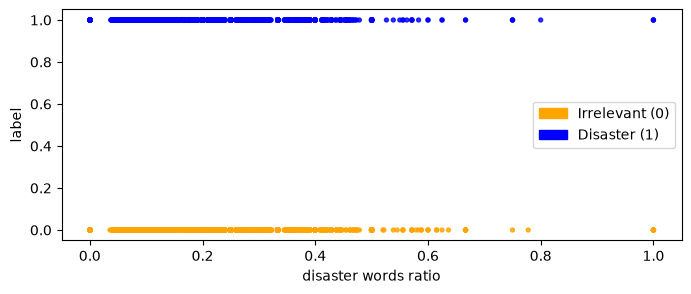

In [57]:
plt.figure(figsize=(8, 3))
colors = {0: 'orange', 1: 'blue'}
plt.scatter(train_df['disaster_words_ratio'], train_df['label'], s=8, alpha=.8,
            c=train_df['label'].map(colors))
plt.legend(handles=[mpatches.Patch(color='orange', label='Irrelevant (0)'),
                    mpatches.Patch(color='blue', label='Disaster (1)')])
plt.xlabel('disaster words ratio'); plt.ylabel('label')
plt.show()

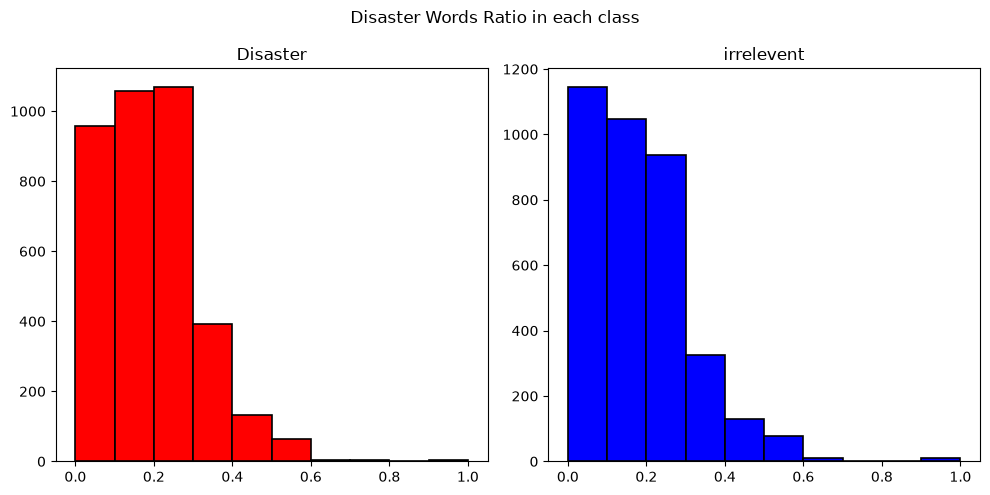

In [58]:
fig,(ax1,ax2) = plt.subplots(1, 2, figsize=(10,5))
disaster_words_ratio1 = train_df[train_df['label'] == 1]['disaster_words_ratio']
ax1.hist(disaster_words_ratio1, color='red',edgecolor='black', linewidth=1.2)
ax1.set_title('Disaster')

disaster_words_ratio2 = train_df[train_df['label'] == 0]['disaster_words_ratio']
ax2.hist(disaster_words_ratio2, color='blue',edgecolor='black', linewidth=1.2)
ax2.set_title('irrelevent')

plt.suptitle("Disaster Words Ratio in each class")
plt.tight_layout()
plt.show()

> ### 🤔 Think
> Look at the two histograms. Is the 'disaster words ratio' a good single feature for classifying tweets? Consider how much the two histograms overlap and how the word list was built (it contained words like `you`, `with`).
>
✅ Check Your Answers

<details>
<summary>Click to reveal the answers and explanations</summary>

No, it’s weak. Both histograms pile up near 0 and overlap heavily. The word list also contains generic words like you and with, because of how it was built.
</details>

My Answer : no, the overlap area is large, and that due to the way of building our disaster words, they have many common words like (you , are , via ....)

In [59]:
train_df.drop('disaster_words_ratio', inplace=True, axis=1)

C:\Users\abd alrahman\AppData\Local\Temp\ipykernel_21356\3056670817.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  train_df.drop('disaster_words_ratio', inplace=True, axis=1)


### 4.2 Two features from the frequency table

Let's use the frequency table in another way. Each word has two counts: how often it appears in **disaster** tweets (class 1) and in **non-disaster** tweets (class 0). For a tweet we **sum** these two counts over all its words, which gives a vector of just **two numbers**:

Let's think of words frequencies in another way:


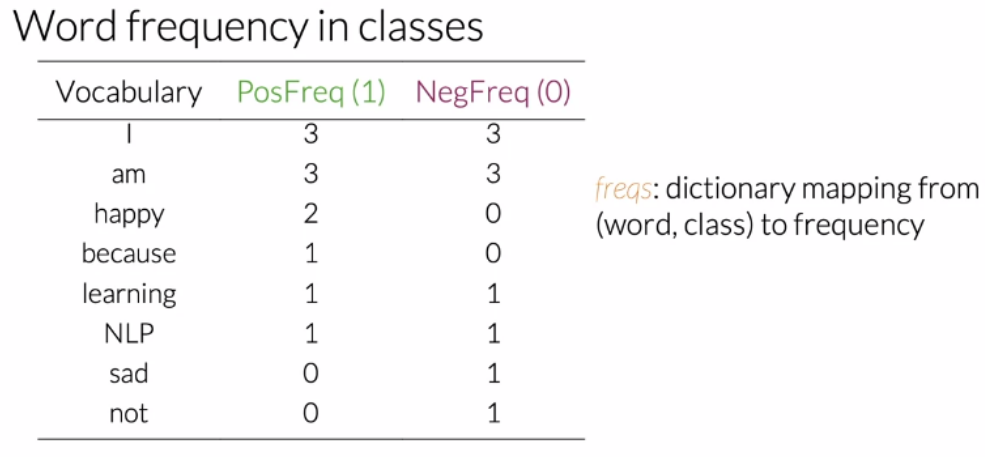


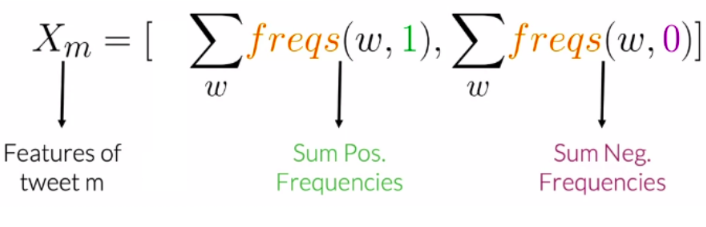

In [60]:
def freq_features(tweet, freqs):
    '''
    Input:
        tweet: one cleaned tweet (a string)
        freqs: dictionary of (word, label) -> frequency
    Output:
        x: a feature vector of shape (1, 2) = [sum of class-1 counts, sum of class-0 counts]
    '''
    word_list = tweet.split()

    x = np.zeros((1, 2))
    for word in word_list:
        x[0, 0] += freqs.get((word, 1), 0)      # how often this word appeared in disaster tweets
        x[0, 1] += freqs.get((word, 0), 0)      # how often this word appeared in non-disaster tweets

    return x

> ### 🎯 Predict
> For the first training tweet, will the first number (disaster counts) be larger or smaller than the second?
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

In [61]:
print(train_df.iloc[0]['cleaned_text'], "| label =", train_df.iloc[0]['label'])
freq_features(train_df.iloc[0]['cleaned_text'], freqs)

angri orchard hard cider recal due to threat of explod bottl | label = 1


array([[2028., 1899.]])

> ### ✏️ Modify
> Replace the tweet below by your own cleaned-style text (lowercase, stemmed: e.g. `huge flood hit citi`, or `love this song`). Is the larger number on the side you expect?
>
> *Edit the **code cell below**, run it, and observe what changes.*

In [62]:
freq_features("huge flood hit citi", freqs)

array([[250.,  95.]])

Now we compute these two features for **every** tweet. The helper `to_matrix` stacks the `(1, 2)` vectors into one table of shape `(number of tweets, 2)`.

In [63]:
def to_matrix(texts, feature_fn, freqs):
    return np.vstack([feature_fn(t, freqs) for t in texts])

X_train_f = to_matrix(train_texts, freq_features, freqs)
X_test_f = to_matrix(test_texts, freq_features, freqs)
print(X_train_f.shape, X_test_f.shape)

(7368, 2) (1852, 2)


**Visualizing the Vectors**: <br>
Now that we've created vectors, let's visualize them and see if we can identify some structure. In a perfect world, our vector would be so distinct that are two classes would be perfectly separated. Since visualizing data in handreds dimensions is hard, let's project it down to 2.

*(The original plot used a very large figure and a `cmap` argument that matplotlib ignored with a warning. The helper below draws the same picture more simply and is reused later.)*

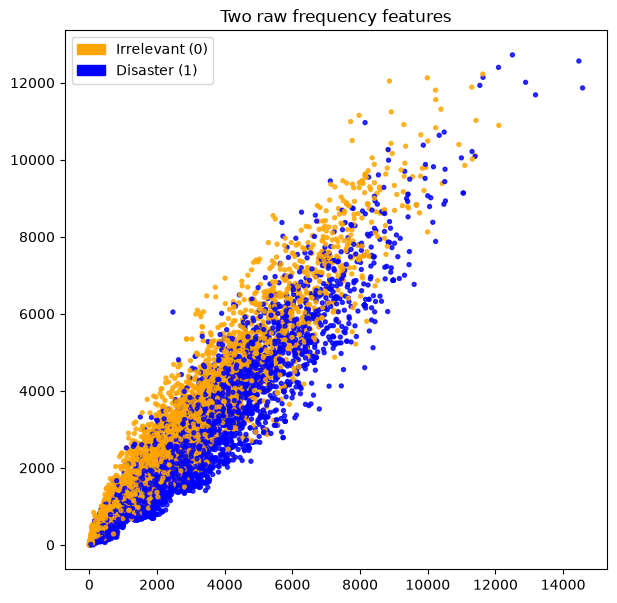

In [64]:
def plot_2d(points, labels, title=''):
    colors = {0: 'orange', 1: 'blue'}
    plt.figure(figsize=(7, 7))
    plt.scatter(points[:, 0], points[:, 1], s=8, alpha=.8, c=[colors[l] for l in labels])
    plt.legend(handles=[mpatches.Patch(color='orange', label='Irrelevant (0)'),
                        mpatches.Patch(color='blue', label='Disaster (1)')])
    plt.title(title)
    plt.show()

plot_2d(X_train_f, y_train, 'Two raw frequency features')

> ### 👀 Observe
> Are the orange and blue points separated, or mixed together? Notice that most points lie along a diagonal. Why do you think long tweets (more words) get large values in **both** coordinates?

Starting with a logistic regression is a good idea. It is simple, often gets the job done, and is easy to interpret.


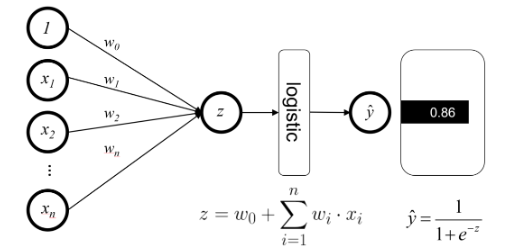

SigmoidFunction_701.svg

**Logistic Regression in plain words.** It multiplies each feature by a learned *weight*, adds the results, and squashes the sum through the **sigmoid** curve into a number between 0 and 1 (a probability). If the probability is above 0.5 it predicts class 1, otherwise class 0.

- `clf.fit(X, y)`: **learn** the weights from the training data.
- `clf.predict(X)`: use the learned weights to **predict labels** for new data.
- `accuracy_score(y_true, y_pred)`: the **fraction of tweets predicted correctly**.

Since we will train many models, we wrap the three steps into one helper function.

In [65]:
def fit_and_score(X_tr, y_tr, X_te, y_te):
    clf = LogisticRegression(random_state=40)
    clf.fit(X_tr, y_tr)                  # learn from the TRAINING data only
    y_predicted = clf.predict(X_te)      # predict the unseen TEST data
    return accuracy_score(y_te, y_predicted), clf

results = {}      # we collect every experiment here and compare them at the end

> ### 🎯 Predict
> Our baseline (always guess the most common class) is about 50%. Roughly what accuracy do you expect from these 2 features: 55%? 70%? 90%?
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

In [66]:
acc, clf = fit_and_score(X_train_f, y_train, X_test_f, y_test)
results['2 features: raw counts'] = acc
print(f"Accuracy: {acc:.4f}")

Accuracy: 0.7068


> ℹ️ If you ever see a `ConvergenceWarning` in the next sections, it only means the optimizer stopped before it fully converged. For our comparisons it is harmless (you can add `max_iter=1000` to `LogisticRegression` if you like).

Could normalizing the frequency could be better? Let's try:

Raw sums grow with tweet length. **Normalizing** divides both numbers by their total, so the two numbers become *shares* that add up to 1 regardless of length. *(Change from the original: we avoid the divide-by-zero warning by checking the total first.)*

In [67]:
def freq_features_normalized(tweet, freqs):
    x = freq_features(tweet, freqs)
    total = x.sum()
    if total == 0:                    # no word of the tweet was seen in training: avoid dividing by zero
        return np.zeros((1, 2))
    return x / total

print(freq_features_normalized(train_df.iloc[0]['cleaned_text'], freqs))

[[0.51642475 0.48357525]]


In [68]:
X_train_n = to_matrix(train_texts, freq_features_normalized, freqs)
X_test_n = to_matrix(test_texts, freq_features_normalized, freqs)

acc, clf = fit_and_score(X_train_n, y_train, X_test_n, y_test)
results['2 features: normalized'] = acc
print(f"Accuracy: {acc:.4f}")

Accuracy: 0.7133


**Remember the stemming dangers!!!**<br>
Let's try the same method without stemming:

We create a second cleaned column **without stemming** (`out_col='cleaned_nostem'`) and rebuild everything from it.

In [69]:
train_df = preprocess_df(train_df, 'text', stem=False, out_col='cleaned_nostem')
test_df = preprocess_df(test_df, 'text', stem=False, out_col='cleaned_nostem')

freqs_ns = build_freqs(train_df['cleaned_nostem'].tolist(), y_train)
X_train_ns = to_matrix(train_df['cleaned_nostem'].tolist(), freq_features_normalized, freqs_ns)
X_test_ns = to_matrix(test_df['cleaned_nostem'].tolist(), freq_features_normalized, freqs_ns)

acc, clf = fit_and_score(X_train_ns, y_train, X_test_ns, y_test)
results['2 features: normalized, no stemming'] = acc
print(f"Accuracy: {acc:.4f}")

Accuracy: 0.7176


> ### 🤔 Think
> Compare the three accuracies in `results`. They are close to each other. Your test set has about 1,800 tweets, so a difference of 0.005 is only about **9 tweets**. Would you conclude that normalization (or removing stemming) *really* helps? What would you do to be more sure?
✅ Check Your Answers

<details>
<summary>Click to reveal the answers and explanations</summary>

No. A gap of 0.005 on about 1,800 tweets is only about 9 tweets, which chance alone can explain. To be more sure, repeat the experiment with different random splits or use cross-validation, and check that the improvement is consistent.
</details>

In [70]:
pd.Series(results)

2 features: raw counts                 0.706803
2 features: normalized                 0.713283
2 features: normalized, no stemming    0.717603
dtype: float64

## 📝 Quick Check — Section 4



*Try every question on paper or in a Markdown cell **before** opening the answers.*

**Q1 (multiple choice).** Why can't we give raw tweets directly to `LogisticRegression`?
- A. It is too slow on text  B. It needs **numeric** features  C. Tweets are too short  D. It only works on lowercase text

**Q2 (code tracing).** `freqs = build_freqs(['good day', 'bad day', 'good good'], [1, 0, 1])`. What is `freqs[('good', 1)]`, and does `('good', 0)` exist as a key?

**Q3 (short answer).** Why must `build_freqs` use only the **training** tweets?

**Q4 (choose the technique).** One tweet has 5 words, another has 30. Which version of our 2 features, raw sums or normalized shares, makes them more comparable? Why?

A1 : B

A2 : 2 , No

A3 : to avoid data leakage 

A4 : Noramlized, since the length differs, the features in the longer tweet are greater than features in the other tweet

## ✅ Check Your Answers — Section 4

<details>
<summary>Click to reveal the answers and explanations <i>(try the questions first!)</i></summary>

**Predict (`build_freqs`):** keys: `('good',1)`, `('day',1)`, `('bad',0)`, `('day',0)`: **4 keys**, each with value 1. (`day` appears once in class 1 and once in class 0.)

**Observe (most frequent pairs):** Yes. `the`, `in`, `to`, `:` are among the most frequent in **both** classes, so they carry almost no information about the class.

**Explain (`extract_disaster_words`):** The comprehension keeps only entries whose class is `label` **and** whose count is `<= threshold` (so extremely common words are dropped). `[:n]` then takes the first `n` of them; because the dictionary was sorted by count, these are the `n` most frequent *remaining* words.

**Modify:** A smaller threshold removes more generic words (`you`, `with`) but may also remove real disaster words; a larger one lets generic words back in. There is no perfect value; this is **hyperparameter tuning**: try, measure, keep the best.

**Think (ratio feature):** It is **weak**. Both histograms are piled up near 0 and overlap a lot, and the word list contains generic words (`you`, `with`, `my`) because of how it was built. A single number cannot separate the classes well.

**Observe (scatter):** The classes are mixed. Points fall along a diagonal because longer tweets accumulate larger sums in *both* coordinates; this is what normalization fixes.

**Predict (accuracy):** About 70% (a bit above 0.7 in the original run). Clearly better than the 50% baseline, but far from perfect.

**Think (noise):** No. A difference of a few tweets can come from chance (which tweets happened to land in the test set). To be more sure you would repeat the experiment with different random splits or use **cross-validation**, and look at whether the improvement is consistent.

**Q1: B.** Models compute with numbers; text must first be converted to numeric features.

**Q2:** `freqs[('good', 1)] = 3` (once in the first tweet, twice in the third). `('good', 0)` does **not** exist as a key, because `build_freqs` only creates pairs that occur. That is why the feature code uses `freqs.get(key, 0)`.

**Q3:** Because the frequencies are *learned* from data. If we also used test tweets, information from the test set would leak into the features (data leakage) and the test accuracy would be too optimistic.

**Q4:** **Normalized shares.** Raw sums grow with the number of words, so the 30-word tweet would simply have bigger numbers; shares add up to 1 for both.

</details>

---
# 5. From Text to Numbers (2): Bag of Words (BoW)

Two numbers per tweet throw away most of the information. **Bag of Words** instead gives every word of the vocabulary its **own column**.

### 5.1 The idea
Motivation: we’re looking for marker words like “excellent” or “disappointed”<br>
Bag of Words (BoW) is a simple and widely used technique for text representation in natural language processing (NLP). It represents text data (documents) as vectors of word counts, disregarding grammar and word order but keeping multiplicity. Each unique word in the corpus is a feature, and the value of each feature is the count of occurrences of the word in the document.


For each token we will have a feature column, this is called **text vectorization**.

Steps to Create BoW Embeddings
- Tokenization:
- Vocabulary Building:<br>
  Create a vocabulary list of all unique words in the corpus.
- Vector Representation:<br>
  For each document, create a vector where each element corresponds to a word in the vocabulary. The value is the count of occurrences of that word in the document.

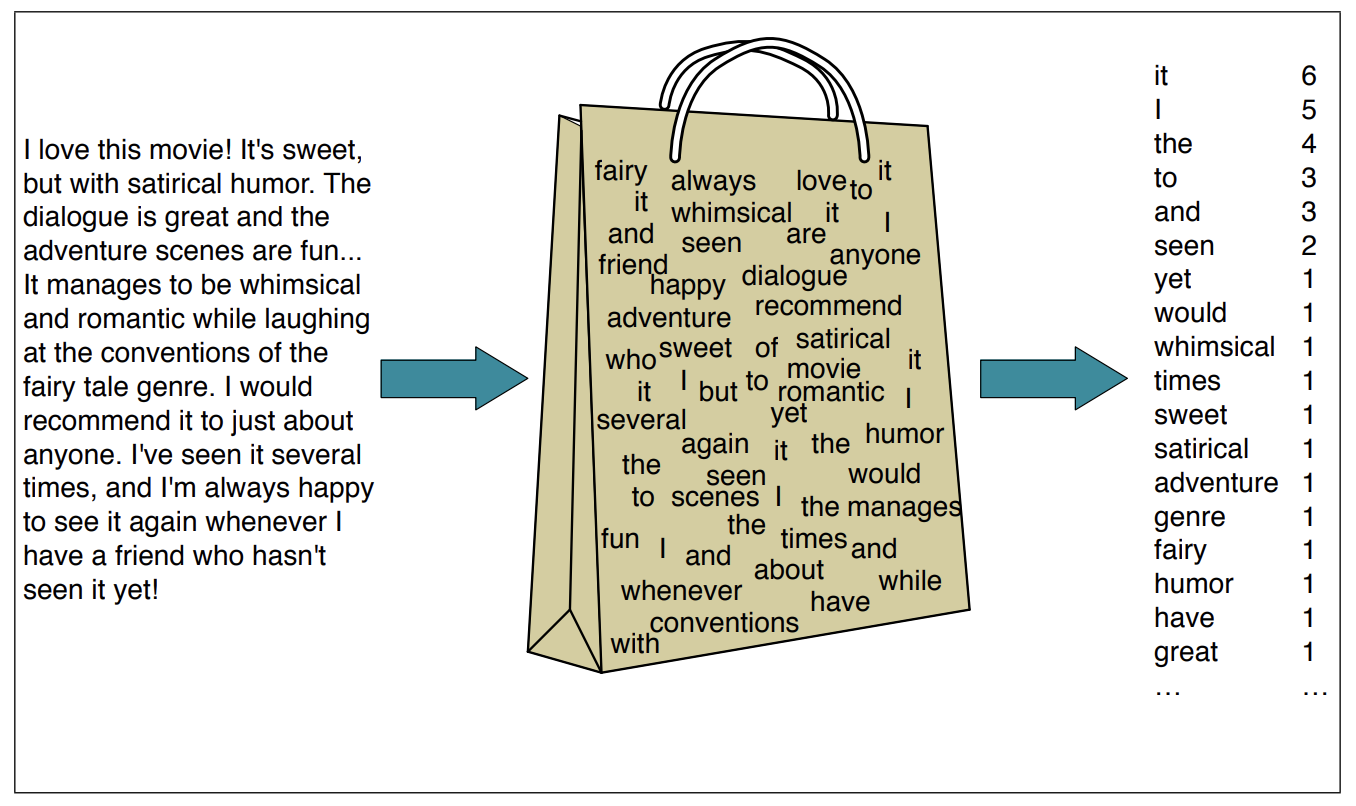

Example:

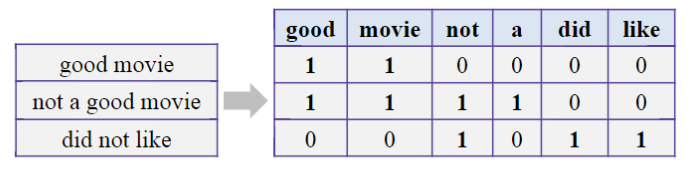

Now in code with scikit-learn's `CountVectorizer`. `fit_transform` does two things: **fit** = learn the vocabulary from the texts; **transform** = turn each text into a vector of word counts. The heat-map shows the 4 sentences as rows and the vocabulary words as columns.

> ### 🎯 Predict
> How many columns (distinct words) will the table have for the 4 sentences below? And what number will appear in the row of `Number three with lot of words words words.` under the column `words`?
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

<Axes: >

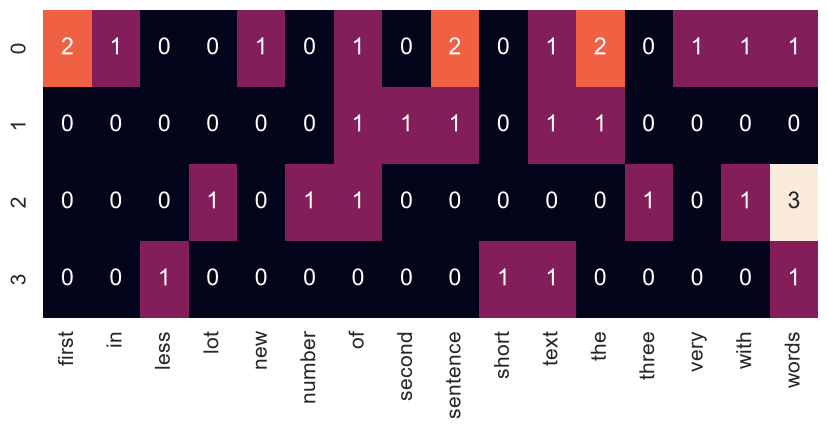

In [71]:
# create CountVectorizer object
vectorizer = CountVectorizer()
corpus = [
          'Text of the very first new sentence with the first words in sentence.',
          'Text of the second sentence.',
          'Number three with lot of words words words.',
          'Short text, less words.',
]
# learn the vocabulary and store CountVectorizer sparse matrix in term_frequencies
term_frequencies = vectorizer.fit_transform(corpus)
vocab = vectorizer.get_feature_names_out()
# convert sparse matrix to numpy array
term_frequencies = term_frequencies.toarray()
# visualize term frequencies
sns.set(font_scale=1.4)
fig, ax = plt.subplots(figsize=(10,4))         # Sample figsize in inches
sns.heatmap(term_frequencies, annot=True, cbar = False, xticklabels = vocab, ax=ax)

In [72]:
print(len(vocab), vocab)

16 ['first' 'in' 'less' 'lot' 'new' 'number' 'of' 'second' 'sentence' 'short'
 'text' 'the' 'three' 'very' 'with' 'words']


Note:
Vectorizers in sklearn return a *sparse matrix*. This is a data type that is optimized for matrices with only a few non-zero elements, which only keeps track of the non-zero elements reducing the memory load.

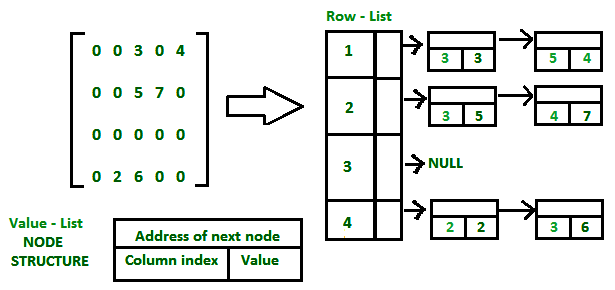

**Binary BoW**: with `binary=True` we only record whether a word is *present* (1) or *absent* (0) instead of counting.

<Axes: >

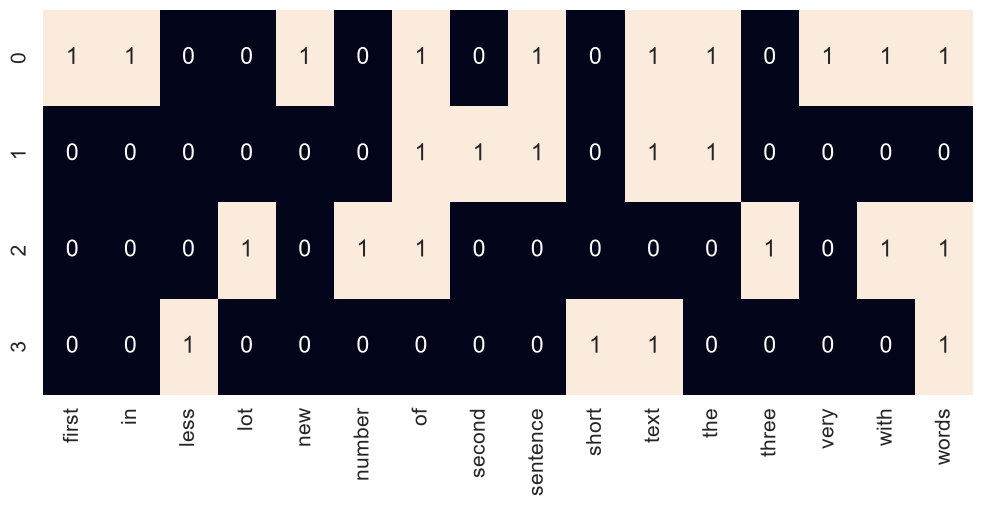

In [73]:
one_hot_vectorizer = CountVectorizer(binary=True)
one_hot = one_hot_vectorizer.fit_transform(corpus).toarray()

sns.set(font_scale=1.4)
fig, ax = plt.subplots(figsize=(12,5))
sns.heatmap(one_hot, annot=True, cbar = False, xticklabels = vocab)

> ### 👀 Observe
> Compare this table with the previous one. In which cells did the numbers change, and why?

### 5.2 BoW on our tweets

> ### 🤔 Think
> Before vectorizing we normalize the text (lowercase, stemming, ...). Why is it important to do this **before** counting words? (Think about `Flood`, `flood`, `floods`, `flooded`.)
>
✅ Check Your Answers

<details>
<summary>Click to reveal the answers and explanations</summary>

Without normalization, Flood, flood, floods and flooded become four separate columns. Counts get spread across near-duplicates. Normalizing merges them into fewer, stronger features.
</details>

My Answer : because if normalized the text after counting , most of the words that we've counted will disappear and always be 0 in the text vectors

**Fit on train, transform on test.** The vocabulary must be learned from the **training** tweets only. The test tweets are then converted with the *same* vocabulary (same columns!), using `transform` (not `fit_transform`).

In [74]:
def cv(data):
    count_vectorizer = CountVectorizer()

    emb = count_vectorizer.fit_transform(data)

    return emb, count_vectorizer

X_train_counts, count_vectorizer = cv(train_texts)
X_test_counts = count_vectorizer.transform(test_texts)

> ### 🐞 Debug
> A student wrote `fit_transform` for the **test** set too. Run the cell below (it uses a tiny example) and read the error.
>
> *The next cell runs but shows a problem. Read the message/output, then fix it in the cell after it.*

In [75]:
train_demo = ["a good day", "a bad day"]
test_demo = ["good movie"]

demo_vec = CountVectorizer()
X_tr_demo = demo_vec.fit_transform(train_demo)          # 3 columns: bad, day, good
demo_clf = LogisticRegression().fit(X_tr_demo, [1, 0])

try:
    X_te_demo = demo_vec.fit_transform(test_demo)       # <-- BUG: learns a NEW vocabulary from the test text
    print(demo_clf.predict(X_te_demo))
except ValueError as error:
    print("Error:", error)

Error: X has 2 features, but LogisticRegression is expecting 3 features as input.


**Fix it** (copy the lines you need and change the buggy one):

In [76]:
# your fixed code here
train_demo = ["a good day", "a bad day"]
test_demo = ["good movie"]

demo_vec = CountVectorizer()
X_tr_demo = demo_vec.fit_transform(train_demo)          # 3 columns: bad, day, good
demo_clf = LogisticRegression().fit(X_tr_demo, [1, 0])

try:
    X_te_demo = demo_vec.transform(test_demo)       # <-- BUG: learns a NEW vocabulary from the test text
    print(demo_clf.predict(X_te_demo))
except ValueError as error:
    print("Error:", error)

[1]


The matrix is stored as a *sparse* matrix, so we look at its `.shape` = *(number of tweets, vocabulary size)*. *(The original called `.toarray()` first, which builds the full dense table and can use gigabytes of memory.)*

In [77]:
X_train_counts.shape

(7368, 12255)

> ### 👀 Observe
> How many columns (features) do we have now compared with only 2 features in Section 4? What does each column represent?

We can't draw 10,000+ dimensions, so for **visualization only** we squash the vectors down to 2 with `TruncatedSVD` (a standard dimensionality-reduction method; this plot is known as LSA). *(Simplified from the original function, same result.)*

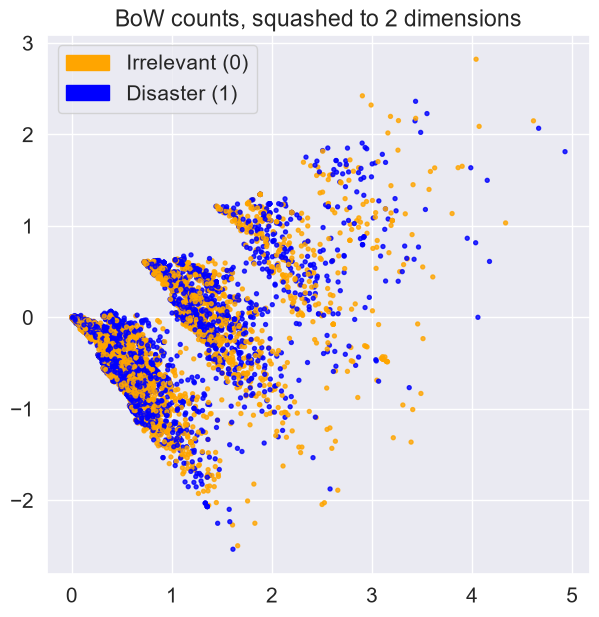

In [78]:
def plot_LSA(vectors, labels, title=''):
    lsa = TruncatedSVD(n_components=2)
    scores = lsa.fit_transform(vectors)
    plot_2d(scores, labels, title)

plot_LSA(X_train_counts, y_train, 'BoW counts, squashed to 2 dimensions')

> ### 🎯 Predict
> With ~12,000 features, will accuracy be higher or lower than with 2 features? Guess a number.
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

In [79]:
acc, clf = fit_and_score(X_train_counts, y_train, X_test_counts, y_test)
results['BoW (counts)'] = acc
print(f"Accuracy: {acc:.4f}")

Accuracy: 0.8191


Since we are going to repeat *vectorize → train → score* many times, we wrap it into one function. It prints the number of features and the accuracy, and stores the result.

In [80]:
def run_bow_experiment(train_text, test_text, name):
    X_tr, vectorizer = cv(list(train_text))
    X_te = vectorizer.transform(list(test_text))
    acc, _ = fit_and_score(X_tr, y_train, X_te, y_test)
    results[name] = acc
    print(f"{name}: {X_tr.shape[1]} features, accuracy = {acc:.4f}")
    return acc

### 5.3 Stop words

Problem:

**High frequency token**:
    - Articles, prepositions, etc. (example: and, a, the)
    - They are called stop-words, they won’t help us to discriminate texts -> remove them
    - actually for 1-grams these words could be removed as a preprocessing step since they are the same for all English texts
    

In [81]:
stop_words = set(stopwords.words('english'))
print(len(stop_words), "stop words, for example:", sorted(stop_words)[:15])

198 stop words, for example: ['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't"]


> ### 👀 Observe
> The list contains negations such as `no`, `not`, `nor` and `don't`. Keep that in mind: we will meet them again in 5.4.

`remove_stopwords` keeps only the words that are **not** in the stop-word set. (Small change from the original: it works on one string and we apply it with `.apply`, instead of creating a new DataFrame column each time.)

In [82]:
def remove_stopwords(text):
    return " ".join(w for w in text.split() if w not in stop_words)

print(remove_stopwords("this is a very big flood in the city"))

big flood city


> ### 🎯 Predict
> Will removing stop words increase the accuracy? Will the number of features go up or down?
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

In [83]:
train_nostop = train_df['cleaned_text'].apply(remove_stopwords)
test_nostop = test_df['cleaned_text'].apply(remove_stopwords)

run_bow_experiment(train_nostop, test_nostop, 'BoW + stop words removed')

BoW + stop words removed: 12175 features, accuracy = 0.8137


0.8137149028077754

> ### 👀 Observe
> Compare with the plain BoW result above (`pd.Series(results)`). Did accuracy go up? Is that what you expected? *Hint:* our text is **stemmed** (`has → ha`) but the stop-word list is not, and the list also deletes negations.

### 5.4 Negation

What is the problem?!<br>
Note the following sentences and the negation words effect on their meaning:<br>

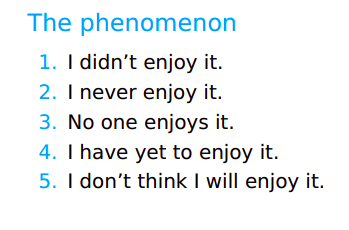

The NLTK stop-word list deletes `no`, `not`, `nor`, `didn't`, ... So *"I do **not** like it"* becomes *"like"*, which **flips the meaning**. A simple fix: replace every negation word by the special token `_NEG` **before** removing stop words, so the negation survives.

In [84]:
negation_words = ['not', 'never', 'neither', 'nor', 'barely','hardly', 'scarcely', 'seldom',
                  'rarely', 'nothing', 'none', 'no', 'nobody','nowhere', 'n\'t']

> ### 🐞 Debug
> Below is the **original** negation function. Run it on the sentence and inspect the output closely. Something is wrong with the word `know`.
>
> *The next cell runs but shows a problem. Read the message/output, then fix it in the cell after it.*

In [85]:
def replace_negations_buggy(tweet, symbol='_NEG'):
    word_list = tweet.split()
    for word in word_list:
        if word in negation_words or word.endswith("n't"):
            tweet = tweet.replace(word, symbol)
    return tweet

print(replace_negations_buggy("i know no one who can help"))

i k_NEGw _NEG one who can help


**Write your own fixed version** below (call it `my_replace_negations`) and test it on the same sentence. Hint: build a new list of tokens instead of calling `.replace` on the whole string.

In [86]:
def replace_negations(tweet, symbol='_NEG'):
    word_list = tweet.split()
    new_tweet = ""
    for word in word_list:
        if word in negation_words or word.endswith("n't"):
            new_tweet += " " + symbol
        else:
            new_tweet += " " + word
    return new_tweet

print(replace_negations("i know no one who can help"))

 i know _NEG one who can help


**Reference version** (run this cell to continue). It works token by token, so `know` is never touched:

In [87]:
def replace_negations(text, symbol='_NEG'):
    words = text.split()
    return " ".join(symbol if (w in negation_words or w.endswith("n't")) else w for w in words)

print(replace_negations("i know no one who can help"))

i know _NEG one who can help


In [88]:
train_neg = train_df['cleaned_text'].apply(replace_negations).apply(remove_stopwords)
test_neg = test_df['cleaned_text'].apply(replace_negations).apply(remove_stopwords)

run_bow_experiment(train_neg, test_neg, 'BoW + stop words + negation marking')

BoW + stop words + negation marking: 12170 features, accuracy = 0.8143


0.8142548596112311

### 5.5 Numbers

What about numbers, they could be useful to distincte disaster tweets (victims count for example) form non-disaster.<br>

let's try:

We test two options: **delete** digits, or **replace** them by the token `_NUM` (we keep the information *"a number was here"*). *(Fix: the original used one option for training and a different one for testing in the second experiment. The same function must be applied to **both** sets.)*

In [89]:
def replace_numbers(text, replacement=''):
    return re.sub(r'\d+', replacement, text)

sample = next((t for t in train_neg if re.search(r'\d', t)), "no number here")
print("before        :", sample)
print("numbers removed:", replace_numbers(sample))
print("numbers -> _NUM:", replace_numbers(sample, '_NUM'))

before        : plain american pipelin compani may spill 40 percent crude oil previous estim
numbers removed: plain american pipelin compani may spill  percent crude oil previous estim
numbers -> _NUM: plain american pipelin compani may spill _NUM percent crude oil previous estim


In [90]:
run_bow_experiment(train_neg.apply(replace_numbers), test_neg.apply(replace_numbers),
                   'BoW + ... + numbers removed')

run_bow_experiment(train_neg.apply(lambda t: replace_numbers(t, '_NUM')),
                   test_neg.apply(lambda t: replace_numbers(t, '_NUM')),
                   'BoW + ... + numbers -> _NUM')

BoW + ... + numbers removed: 11410 features, accuracy = 0.8083
BoW + ... + numbers -> _NUM: 11572 features, accuracy = 0.8105


0.8104751619870411

> ### 🤔 Think
> Look at all BoW results in `pd.Series(results)`. Which preprocessing steps helped, which hurt? Remember the lesson from Section 4 about differences of a few tweets. Which conclusions would you trust?
>
✅ Check Your Answers

<details>
<summary>Click to reveal the answers and explanations</summary>

The big jump comes from going from 2 features to Bag of Words. Stop-word removal, negation marking and number handling each change accuracy by well under a point, which is a handful of tweets. Don’t over-interpret them.
</details>

BOW helped, the other things difference is very small, we need more data or using K-fold CV to make sure that the STD between expirements is small

In [91]:
pd.Series(results)

2 features: raw counts                 0.706803
2 features: normalized                 0.713283
2 features: normalized, no stemming    0.717603
BoW (counts)                           0.819114
BoW + stop words removed               0.813715
BoW + stop words + negation marking    0.814255
BoW + ... + numbers removed            0.808315
BoW + ... + numbers -> _NUM            0.810475
dtype: float64

### 5.6 Keeping some word order: n-grams

Another Problems:<br>
   - We lose word order, hence the name “bag of words”, This means that “Apple is looking at buying a U.K. startup.” and “Startup is looking at buying an Apple.” will have the same BoW representation, despite having different meanings.
   - Counters are not normalized.

   ***Let's preserve some ordering***<br>
We can count token pairs, triplets, etc. Also known as **n-grams**


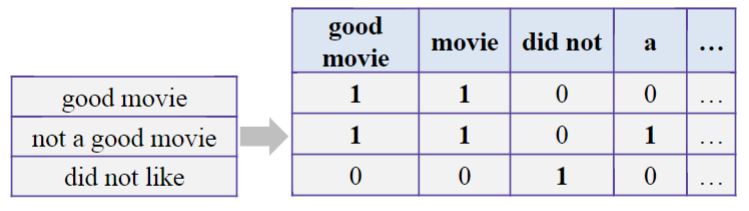

> ### 🎯 Predict
> `CountVectorizer(ngram_range=(1,2))` counts single words **and** pairs of consecutive words. On the 4-sentence `corpus` will there be more or fewer columns than before (16)?
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

<Axes: >

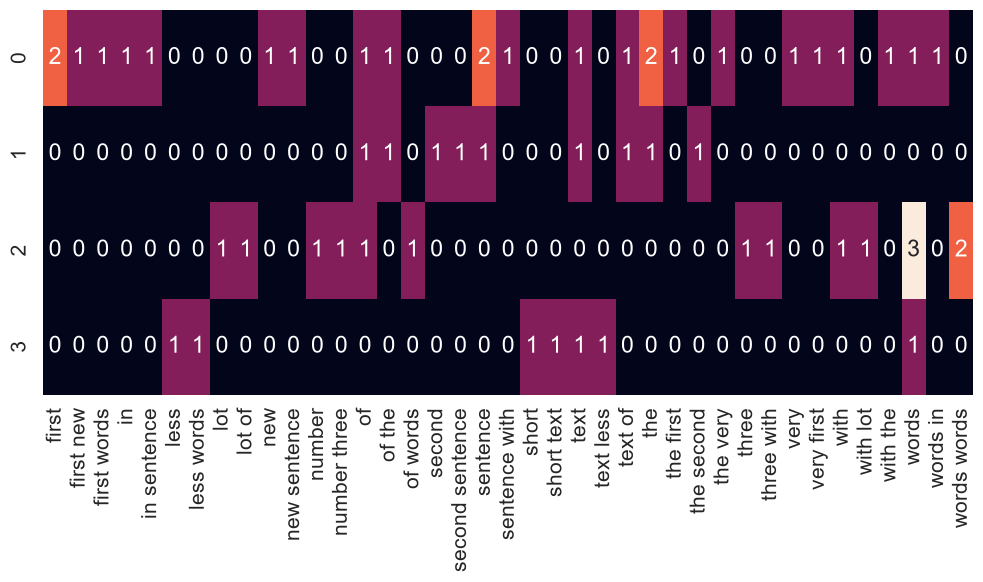

In [92]:
vectorizer = CountVectorizer(ngram_range=(1,2))
ngrams = vectorizer.fit_transform(corpus).toarray()

vocab = vectorizer.get_feature_names_out()

sns.set(font_scale=1.4)
fig, ax = plt.subplots(figsize=(12,5))
sns.heatmap(ngrams, annot=True, cbar = False, xticklabels = vocab)

> ### ✏️ Modify
> Run the next cell with `ngram_range=(1, 2)`, then try `(1, 1)` and `(1, 3)`, and change `min_df`. How do the number of features and the accuracy change? (`min_df=2` = ignore n-grams that appear in fewer than 2 tweets.)
>
> *Edit the **code cell below**, run it, and observe what changes.*

In [93]:
vec = CountVectorizer(ngram_range=(1, 2), min_df=1)       # <-- edit me
X_tr = vec.fit_transform(train_df['cleaned_text'])
X_te = vec.transform(test_df['cleaned_text'])
acc, _ = fit_and_score(X_tr, y_train, X_te, y_test)
print(X_tr.shape[1], "features, accuracy =", round(acc, 4))

66568 features, accuracy = 0.8143


<details>
<summary>📖 <b>Read at Home:</b> everything that is wrong with Bag of Words <i>(optional, click to expand)</i></summary>

BoW Problems:<br>
- High Dimensionality
  - Large Vocabulary Size:<br>
    The dimensionality of BoW vectors is equal to the number of unique words in the corpus, which can be extremely large. This leads to very high-dimensional vectors, resulting in increased computational cost and memory usage.
  - Sparsity:<br>
    Most documents use only a small fraction of the total vocabulary, resulting in sparse vectors with many zero values. This sparsity can make storage and computation inefficient.
- Lack of Contextual Information
  - Word Order Ignored
  - Loss of Syntax and Semantics:
    The embedding does not capture syntactic and semantic relationships between words. For instance, “bank” in the context of a financial institution and “bank” in the context of a riverbank will have the same representation.
- Lack of Handling of Synonymy<br>
  Synonyms (different words with similar meaning) are treated as completely unrelated features. For example, “happy” and “joyful” will have different vector representations even though they have similar meanings.
- Fixed Vocabulary<br>
  BoW cannot handle words that were not present in the training corpus. Any new word encountered will be ignored or misrepresented, leading to potential loss of information.
- Feature Independence Assumption
  No Inter-Feature Relationships: BoW assumes that the presence or absence of a word in a document is independent of other words. This independence assumption ignores any potential relationships or dependencies between words, which can be crucial for understanding context and meaning.
- Scalability Issues<BR>
  Computational Inefficiency: As the size of the corpus increases, the vocabulary size also increases, leading to scalability issues. High-dimensional vectors require more computational resources for processing, storing, and analyzing the data.
- No Weighting Mechanism<BR>
  Equal Importance: In its simplest form, BoW treats all words with equal importance, which is not always appropriate. Common but less informative words (e.g., “the”, “is”) are treated the same as more informative words (e.g., “cat”, “bank”).
- Lack of Generalization<BR>
  Poor Performance on Short Texts: BoW can be particularly ineffective for short texts or documents with limited content, where the lack of context and the sparse nature of the vector representation can lead to poor performance.

</details>

## 📝 Quick Check — Section 5



*Try every question on paper or in a Markdown cell **before** opening the answers.*

**Q1 (code tracing).** `CountVectorizer().fit_transform(["go home now", "go go home"])`. The columns are sorted alphabetically: `go`, `home`, `now`. What are the two rows?

**Q2 (multiple choice).** Which pair of sentences gets the **same** Bag-of-Words vector?
- A. "dog bites man" / "man bites dog"   B. "good movie" / "not good movie"   C. "I like it" / "I like them"   D. "fire" / "fires"  (no stemming)

**Q3 (true/false + justify).** *"Removing stop words always improves accuracy."*

**Q4 (choose the technique).** You want the classifier to treat *"not good"* differently from *"good"* **without** adding a special `_NEG` token. Which `CountVectorizer` setting helps?

**Q5 (short answer).** Why do we call `fit_transform` on the training texts but only `transform` on the test texts?

A1 : 

 row1 : 1 1 1

 row2 : 2 1 0

A2 : A, B if we removed negations, 

A3 : Not necessary, since removing them also removes negation, that leads to the opposite meaning and to wrong results

A4 : idk

A5 : fit_transorm calculates somthing from the data, transform applies something from the calculated stuff on the data, since test data should simulate real life, we wont use fit on it since it would make data leakage, we only transform it according to what we saw in the train data

## ✅ Check Your Answers — Section 5

<details>
<summary>Click to reveal the answers and explanations <i>(try the questions first!)</i></summary>

**Think (normalize before vectorizing):** Without normalization `Flood`, `flood`, `floods` and `flooded` become **four different columns**. Counts are spread thin over many near-duplicates; normalizing merges them so the classifier sees fewer, stronger features.

**Predict (corpus):** **16** columns (the vocabulary); the number in that cell is **3**.

**Observe (binary):** Every number greater than 1 became 1 (e.g. `words` in sentence 3, and `the`, `first`, `sentence` in sentence 1). Zeros stay zeros.

**Debug (fit_transform on test):** The new vocabulary of the test text has a different number of columns than the model expects (*"X has 2 features, but LogisticRegression is expecting 3 features"*). Even when the numbers happen to match, the columns would mean *different words*, so predictions would be silently wrong. Fix: `demo_vec.transform(test_demo)`.

**Observe (features):** Roughly **10,000+ columns** instead of 2. Each column is one distinct word (vocabulary entry) and the value is how many times it occurs in the tweet.

**Predict (accuracy):** **Higher**, around 80% instead of 70%. The classifier can now learn a weight for each individual word (e.g. `earthquak` strongly positive).

**Observe (stop words):** Accuracy changes only slightly and may even drop a little. Removing stop words is *not* automatically a win: it also removes words that carry meaning here (negations, pronouns), and our stemmed text does not match the unstemmed stop-word list perfectly.

**Debug (negations):** The buggy output is `i k_NEGw _NEG one who can help`. `tweet.replace('no', '_NEG')` replaces **every occurrence of the characters `no`**, also inside other words (`know`). Fix: process word by word, e.g. `" ".join('_NEG' if w in negation_words else w for w in text.split())`.

**Think (what helped?):** Typically the big jump comes from going from 2 features to BoW. The later steps (stop words, negation marking, numbers) change accuracy by well under one point, i.e. a handful of tweets, so we should **not** over-interpret them. Trust the large, consistent effects.

**Predict (n-grams):** **More** columns: every pair of neighbouring words becomes an extra feature.

**Modify (n-grams):** More n-gram range → many more features; `min_df` prunes rare ones. Accuracy may rise slightly or not at all.

**Q1:** Row 1 = `[1, 1, 1]`; row 2 = `[2, 1, 0]` (`go` twice, `home` once, `now` never).

**Q2: A.** BoW ignores order, so both sentences contain exactly the same words. (B differs by `not`, C by `it`/`them`, D by the word form.)

**Q3: False.** In our experiment it did not clearly help, and the NLTK list removes negations such as `not`, which can **flip** the meaning. Whether it helps depends on the task and must be tested.

**Q4:** `ngram_range=(1, 2)`: the bigram `not good` becomes its own feature.

**Q5:** The vocabulary must come from the training data only (no leakage), and the test vectors must have **exactly the same columns** as the training vectors, so we reuse the already-learned vocabulary with `transform`.

</details>

---
# 6. From Text to Numbers (3): TF-IDF

Plain counts treat every word as equally important. Intuition for a **better weighting**:

- A word that appears in **almost every** tweet (`the`, `to`) says very little → give it a **low** weight.
- A word that appears in **few** tweets (`tsunami`) but several times in *this* tweet says a lot → give it a **high** weight.
- Typos and extremely rare n-grams cause **overfitting** (the model memorizes them) → drop them.

Let’s remove some n-grams from features based on their occurrence frequency in documents of our corpus to handle High Dimensionality problem:

**Low frequency n-grams:**<br>
- Typos, rare n-grams
- We don’t need them either, otherwise we will likely **overfit**



**Medium frequency n-grams:** <br>
- Those are good n-grams



*There’re a lot of medium frequency n-grams*
- It proved to be useful to look at **n-gram frequency in our corpus** for filtering out bad n-grams
- What if we use it for **ranking** of medium frequency n-grams?
- **Idea**: the n-gram with smaller frequency can be more discriminating because it can capture a characteristics in the text (**reweighting** raw counts)


#### TF-IDF
Term frequency (TF) <br>
**tf(*t*,*d*)** –frequency for term (or n-gram) *t*  in document *d*

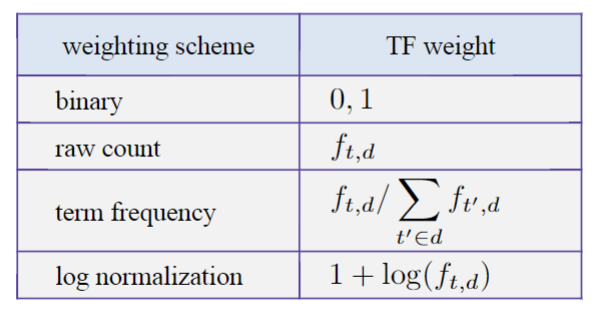

log: gives logarithmic scale to the counts

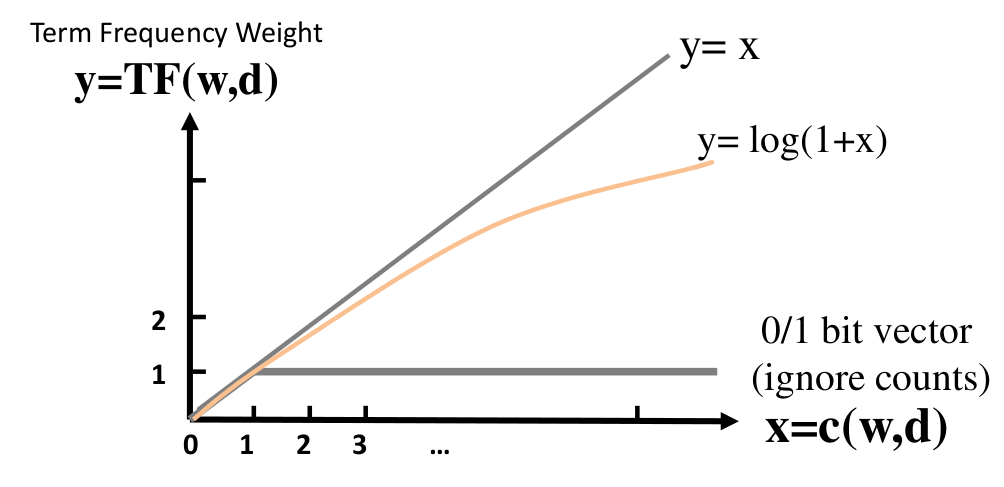

### TF-IDF
\begin{equation*}tfidf(t,d,D) = tf(t,d) × idf(t,D) \end{equation*}<br>

Inverse Document Frequency(IDF): the inverse document frequency of the word across a collection of documents. Rare words have high scores, common words have low scores.<br>

\begin{align}
tf(t, d) = \frac{Number\ of\ times\ term\ t\ appears\ in\ a\ document\ d}{Total\ number\ of\ terms\ in\ the\ document\ d}
\end{align}

\begin{align}
IDF(t, D)=log\frac{Total\ number\ of\ documents\ D}{Number\ of\ documents\ with\ term\ t\ in\ it}
\end{align}

A high weight in TF-IDF is reached by a high term frequency(in the given document) and a low document frequency of the term in the whole collection of documents


## Better BOW
- Replace counters with TF-IDF
- Normalize the result row-wise (e.g. divide by L2-norm (the root of the sum of the squares of all elements))

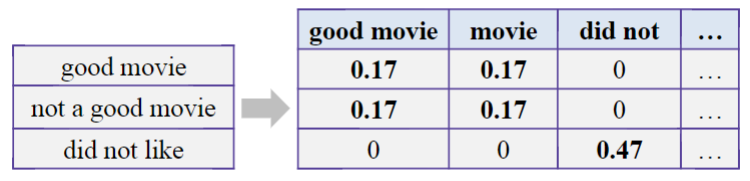

> 📝 **Note.** The formulas above are the textbook version. `TfidfVectorizer` uses a slightly *smoothed* version of IDF and finally **normalizes each row** so that its length is 1 (L2 norm). The ideas are the same.

> ### 🎯 Predict
> Five tiny texts, with `min_df=2` (keep n-grams that appear in ≥ 2 texts) and `max_df=0.5` (drop n-grams that appear in more than 50% of the texts). The word `good` appears in 3 of the 5 texts. Which text will get an **all-zero** row, and why?
>
> *No need to write anything down. Commit to a guess **before** you run the next cell, then compare.*

In [94]:
texts = ["good movie", "not a good movie", "did not like", "i like it", "good one"]
# using default tokenizer in TfidfVectorizer
tfidf = TfidfVectorizer(min_df=2, max_df=0.5, ngram_range=(1, 2))
tfidf.fit(texts) #calcualate the values
features = tfidf.transform(texts) #make the vectors
pd.DataFrame(
    features.todense(),
    columns=tfidf.get_feature_names_out()
)

,good movie,like,movie,not
0,0.707107,0.000000,0.707107,0.000000
1,0.577350,0.000000,0.577350,0.577350
2,0.000000,0.707107,0.000000,0.707107
3,0.000000,1.000000,0.000000,0.000000
4,0.000000,0.000000,0.000000,0.000000


max_df is used for removing terms that appear too frequently, also known as "corpus-specific stop words". For example:<br>

- max_df = 0.50 means "ignore terms that appear in more than 50% of the documents".<br>
- max_df = 25 means "ignore terms that appear in more than 25 documents".<br>

The default max_df is 1.0, which means "ignore terms that appear in more than 100% of the documents". Thus, the default setting does not ignore any terms.<br>


min_df is used for removing terms that appear too infrequently. For example:<br>

- min_df = 0.01 means "ignore terms that appear in less than 1% of the documents".<br>
- min_df = 5 means "ignore terms that appear in less than 5 documents".<br>

The default min_df is 1, which means "ignore terms that appear in less than 1 document". Thus, the default setting does not ignore any terms.

> ### ✏️ Modify
> In the demo above set `min_df=1` and `max_df=1.0` (keep everything) and re-run. How does the table change?
>
> *Edit the **code cell below**, run it, and observe what changes.*

In [95]:
texts = ["good movie", "not a good movie", "did not like", "i like it", "good one"]
tfidf_demo = TfidfVectorizer(min_df=1, max_df=1.0, ngram_range=(1, 2))      # <-- edit me
tfidf_demo.fit(texts)
features = tfidf_demo.transform(texts)
pd.DataFrame(features.todense(), columns=tfidf_demo.get_feature_names_out()).round(2)

,did,did not,good,good movie,good one,it,like,like it,movie,not,not good,not like,one
0,0.00,0.00,0.51,0.61,0.00,0.00,0.00,0.00,0.61,0.00,0.00,0.00,0.00
1,0.00,0.00,0.36,0.44,0.00,0.00,0.00,0.00,0.44,0.44,0.54,0.00,0.00
2,0.48,0.48,0.00,0.00,0.00,0.00,0.39,0.00,0.00,0.39,0.00,0.48,0.00
3,0.00,0.00,0.00,0.00,0.00,0.61,0.50,0.61,0.00,0.00,0.00,0.00,0.00
4,0.00,0.00,0.43,0.00,0.64,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.64


**On our tweets.** *(Bug fixed: in the original, `tfidf(data, min_df, max_df)` ignored its own parameters (the values `10` and `0.75` were hard-coded) and was then called without them, which raises a `TypeError`. Now the parameters are used and have default values.)*

In [96]:
def tfidf(data, min_df=10, max_df=0.75):
    tfidf_vectorizer = TfidfVectorizer(min_df=min_df, max_df=max_df, ngram_range=(1, 2))
    train = tfidf_vectorizer.fit_transform(data)
    return train, tfidf_vectorizer

X_train_tfidf, tfidf_vectorizer = tfidf(train_texts)
X_test_tfidf = tfidf_vectorizer.transform(test_texts)
print(X_train_tfidf.shape)

(7368, 2247)


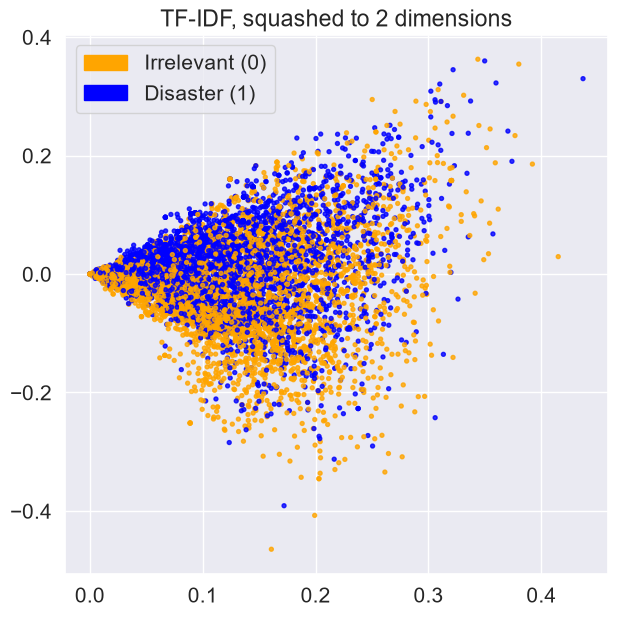

In [97]:
plot_LSA(X_train_tfidf, y_train, 'TF-IDF, squashed to 2 dimensions')

In [98]:
acc, clf = fit_and_score(X_train_tfidf, y_train, X_test_tfidf, y_test)
results['TF-IDF (1-2 grams, min_df=10, max_df=0.75)'] = acc
print(f"Accuracy: {acc:.4f}")

Accuracy: 0.8148


> ### ✏️ Modify
> Call `tfidf(train_texts, min_df=5, max_df=0.5)` (and transform the test texts with the *new* vectorizer). Do the number of features and the accuracy change much?
>
> *Edit the **code cell below**, run it, and observe what changes.*

In [99]:
X_tr, vec = tfidf(train_texts, min_df=5, max_df=0.2)       # <-- edit me
X_te = vec.transform(test_texts)
acc, _ = fit_and_score(X_tr, y_train, X_te, y_test)
print(X_tr.shape[1], "features, accuracy =", round(acc, 4))

4684 features, accuracy = 0.817


### 6.1 All experiments side by side

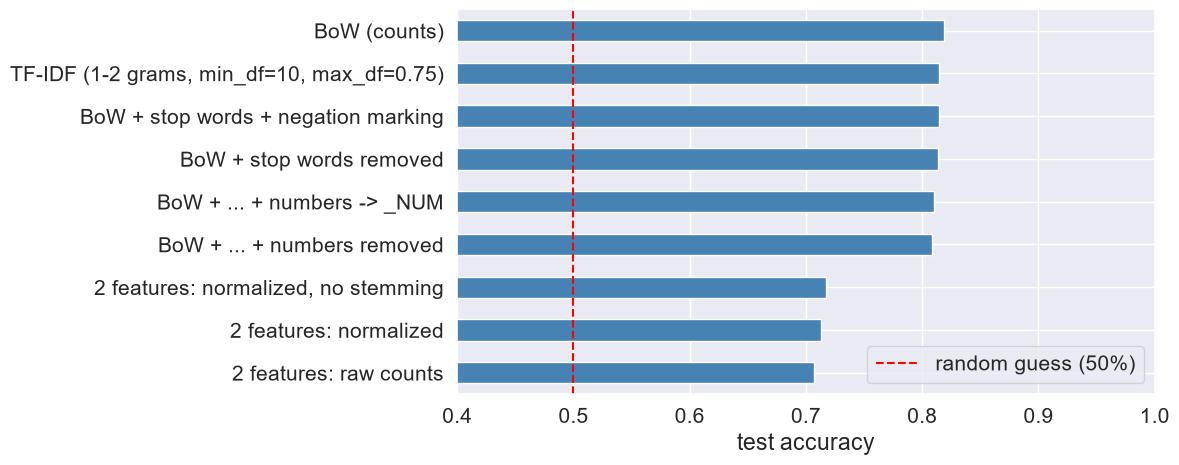

2 features: raw counts                        0.7068
2 features: normalized                        0.7133
2 features: normalized, no stemming           0.7176
BoW (counts)                                  0.8191
BoW + stop words removed                      0.8137
BoW + stop words + negation marking           0.8143
BoW + ... + numbers removed                   0.8083
BoW + ... + numbers -> _NUM                   0.8105
TF-IDF (1-2 grams, min_df=10, max_df=0.75)    0.8148
dtype: float64

In [100]:
summary = pd.Series(results)
ax = summary.sort_values().plot.barh(figsize=(9, 5), color='steelblue')
ax.axvline(0.5, color='red', linestyle='--', label='random guess (50%)')
ax.set_xlim(0.4, 1.0); ax.set_xlabel('test accuracy'); ax.legend()
plt.show()
summary.round(4)

> ### 🤔 Think
> Summarize in 3 sentences what you learned from this chart: which change made the **biggest** difference, and which differences are too small to trust?
>
> *Answer in this cell: double-click, type below the line, then press Shift+Enter. Compare with the sample answer in **Check Your Answers** at the end of the section.*

✍️ **Your answer:** *(double-click to edit)*

BOW made the biggest difference, the other small changes are not trusted due to the small data size

In general, Raw frequency is very skewed and not very discriminative.

<details>
<summary>📖 <b>Read at Home:</b> limits of TF-IDF and the BM25 idea <i>(optional, click to expand)</i></summary>

TFIDF problems:
In addtion to BoW lack of context and semantic understanding problems we have:
- Bias Towards Rare Terms <br>
  While the IDF component of TF-IDF aims to balance the frequency of terms, it can sometimes overly emphasize rare terms. This might lead to overvaluing words that appear infrequently but are not necessarily more relevant or important in the context of the document.

- Normalization Issues
  The normalization process in TF-IDF (e.g., dividing by the total number of words in a document) may not always be effective in balancing document lengths and word frequencies, potentially leading to skewed results.<br>
  If a document contains 100 occurrences of the term “computer,” is it really twice as relevant as a document that contains 50 occurrences? We could argue that if the term “computer” occurs a large enough number of times, the document is almost certainly relevant, and any more occurrences doesn’t increase the likelihood of relevance. So, we want to control the contribution of TF when a term is likely to be saturated.

---

##### Best Match 25 (BM25)

BM25 is a probabilistic retrieval framework that extends the idea of TF-IDF and improves some drawbacks of TF-IDF which concern with term saturation and document length.

BM25 solves this issue by introducing a parameter k that controls the shape of this saturation curve preventing a term’s frequency from having an unbounded impact on the document’s relevance.

In addtion, BM25 introduces a sophisticated way of handling document length. Unlike TF-IDF, which may unfairly penalize longer documents, BM25 normalizes for length in a more balanced manner, reducing the impact of document length on the calculation of relevance.


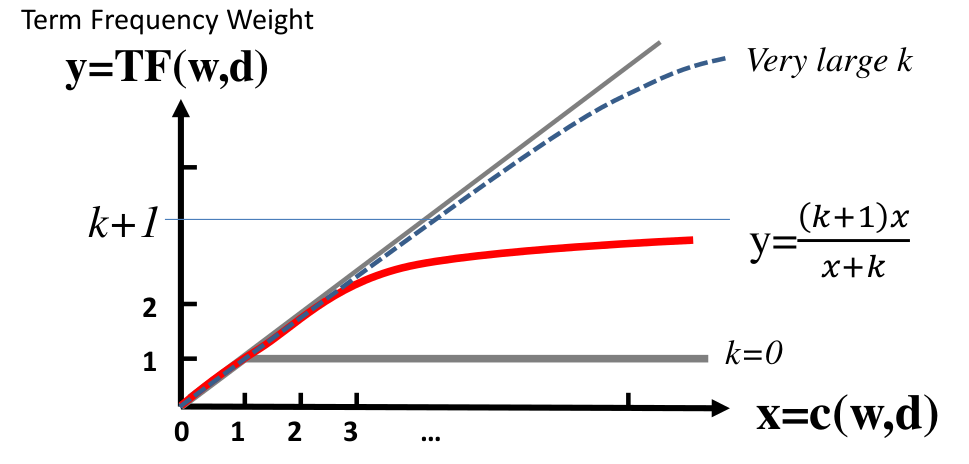

</details>

In [101]:
# TODO READ THIS SECTION BELLOW !

<details>
<summary>📖 <b>Read at Home:</b> word–word (co-occurrence) matrices and PMI <i>(optional, click to expand)</i></summary>

##### Term-term matrix

An alternative to using the **term-document matrix** to represent words as vectors of
document counts, is to use the **term-term matrix**, also called the **word-word matrix** or the **term-context matrix** or **co-occurrence matrix**, in which the columns are labeled by words rather  than documents. This matrix is thus of dimensionality |V|×|V| and each cell records
the number of times the row (target) word and the column (context) word co-occur
in some context in some training corpus. The context could be the document, in
which case the cell represents the number of times the two words appear in the same
document. It is most common, however, to use smaller contexts, generally a window around the word, for example of 4 words to the left and 4 words to the right,
in which case the cell represents the number of times (in some training corpus) the
column word occurs in such a ±4 word window around the row word. Here are four
examples of words in their windows:

<center>is traditionally followed by <font color='gray'>cherry</font> pie, a traditional dessert <br>
often mixed, such as <font color='gray'>strawberry</font> rhubarb pie. Apple pie<br>
computer peripherals and personal <font color='gray'>digital</font> assistants. These devices usually<br>
a computer. This includes <font color='gray'>information</font> available on the internet</center>

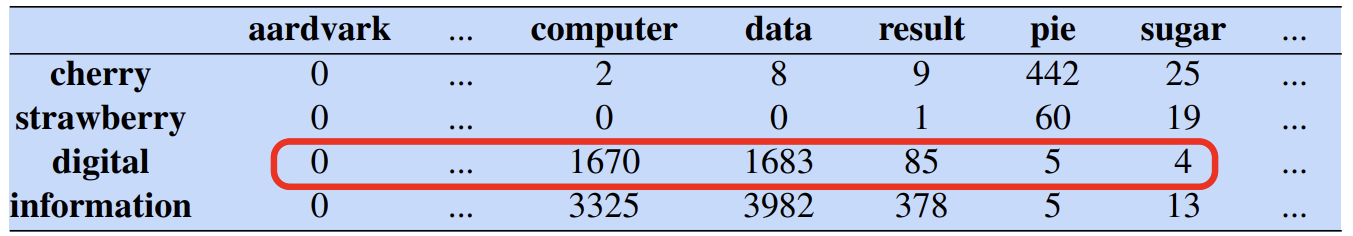

---

##### Pointwise Mutual Information (PMI)

An alternative weighting function to tf-idf, PPMI (positive pointwise mutual information), is used for term-term-matrices. PPMI draws on the intuition that the best way to weigh
the association between two words is to ask how much more the two words co-occur
in our corpus than we would have a priori expected them to appear by chance.

The pointwise mutual information between a target word w and a context word c:

\begin{align}
PMI(w,c) = \log\frac{p(w,c)}{p(w)\,p(c)}
\end{align}

</details>

## 📝 Quick Check — Section 6



*Try every question on paper or in a Markdown cell **before** opening the answers.*

**Q1 (multiple choice).** In TF-IDF, which word gets the **highest IDF**?
- A. A word in 99 of 100 tweets  B. A word in 50 of 100 tweets  C. A word in 1 of 100 tweets  D. All get the same IDF

**Q2 (true/false + justify).** *"TF-IDF knows the order of words in a tweet."*

**Q3 (short answer).** You use `TfidfVectorizer(min_df=3)`. A tweet consists only of words that appear in 1 or 2 training tweets. What will its vector look like?

A1 : C

A2 : No , it only uses frequencies

A3 : all zeros

## ✅ Check Your Answers — Section 6

<details>
<summary>Click to reveal the answers and explanations <i>(try the questions first!)</i></summary>

**Predict (demo):** Row 4, `good one`: `good` is dropped by `max_df` (it is in 60% of the texts) and `one` appears only once (dropped by `min_df=2`), so **no feature is left** and the row is all zeros. Texts that lose all their features become zero vectors.

**Modify (demo):** With `min_df=1, max_df=1.0` every word and bigram is kept, so the table has many more columns and no all-zero rows.

**Think (summary):** The biggest jump is from 2 features to BoW/TF-IDF (~70% → ~82%). TF-IDF and the preprocessing variants differ from plain BoW by a few tenths of a point, which is only a handful of tweets, so those differences are too small to trust without repeated experiments.

**Q1: C.** IDF is large for words that are in **few** documents (rare words) and small for words in almost all documents.

**Q2: False.** With unigrams it counts words just like BoW. Only n-grams (e.g. `ngram_range=(1, 2)`) capture a little local order.

**Q3:** An **all-zero vector**. All of its words are removed by `min_df=3`, so the tweet has no features. (A classifier then predicts based on its bias term only.)

</details>

## Hands on Exercies Spam or Ham?  (≈ 40 min)

Now it's your turn. **Same pipeline, new problem:** decide whether an SMS message is **spam** or **ham** (a normal message).

| Step | What you do|
|---|---|
| 1 | Load the data and split it
| 2 | Explore the training data
| 3 | Clean the text
| 4 | Baseline: Bag-of-Words + Logistic Regression
| 5 | Improve it: run 3+ experiments and fill the scoreboard
| 6 | Error analysis + discussion | the rest |

**How to work**
- Work in pairs. Reuse any code from Part 1 — copy–paste is allowed, understanding is required.
- Fill in every `# TODO` (replace the `...`). Cells with `assert` tell you if you are on track.
- Write your observations in the ✏️ cells: they are what we will discuss at the end.
- Fast finishers: do the **Bonus** at the end.

### Task 0 — Load the data (given)

**SMS Spam Collection** (Almeida & Hidalgo, UCI): about 5,570 English text messages, each labelled `ham` (legitimate) or `spam`.

In [102]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
from nltk.stem import PorterStemmer

URL = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"

if os.path.exists("sms_spam.csv"):        # offline copy, if your teacher shared one
    sms = pd.read_csv("sms_spam.csv")
else:
    sms = pd.read_csv(URL, sep="\t", header=None, names=["label", "text"])

sms["label"] = sms["label"].map({"ham": 0, "spam": 1})    # 1 = spam
print(sms.shape)
sms.sample(8, random_state=1)

(5572, 2)


,label,text
1078,0,"Yep, by the pretty sculpture"
4028,0,"Yes, princess. Are you going to make me moan?"
958,0,Welp apparently he retired
4642,0,Havent.
4674,0,I forgot 2 ask ü all smth.. There's a card on ...
5461,0,Ok i thk i got it. Then u wan me 2 come now or...
4210,0,I want kfc its Tuesday. Only buy 2 meals ONLY ...
4216,0,No dear i was sleeping :-P


### Task 1 — Split first!

Split into **80 % train / 20 % test** with `random_state=40`.
Spam is much rarer than ham, so add `stratify=y_all`: both sets then keep the same share of spam.

> ❓ Why do we split *before* exploring the data?

In [103]:
X_all = sms["text"].tolist()
y_all = sms["label"].tolist()

# TODO 1: split into X_train_sms, X_test_sms, y_train_sms, y_test_sms
X_train_sms, X_test_sms, y_train_sms, y_test_sms = train_test_split(X_all , y_all , test_size = 0.2 , random_state= 40 , stratify= y_all)

assert len(X_train_sms) + len(X_test_sms) == len(sms), "Did you split all the data?"
print(len(X_train_sms), "train /", len(X_test_sms), "test")

sms_train = pd.DataFrame({"text": X_train_sms, "label": y_train_sms})
sms_test = pd.DataFrame({"text": X_test_sms, "label": y_test_sms})

4457 train / 1115 test


### Task 2 — Explore the **training** data

Use `sms_train` only (never look at the test set while you make decisions).

In [104]:
# TODO 2a: how many ham / spam messages are in sms_train? Show counts AND percentages
spam_cnt = len(sms_train[sms_train['label'] == 1])
spam_perc = spam_cnt / len(sms_train)
print(f"Spam Count: {spam_cnt}, Percentage : {spam_perc}") 
ham_cnt = len(sms_train[sms_train['label'] == 0])
ham_perc = ham_cnt / len(sms_train)
print(f"Ham Count: {ham_cnt}, Percentage : {1 - spam_perc}") 

Spam Count: 598, Percentage : 0.13417096701817366
Ham Count: 3859, Percentage : 0.8658290329818263


In [105]:
# TODO 2b: accuracy on the TEST set of a "model" that always predicts ham (0)
y_pred_dum = np.zeros_like(y_test)
baseline_acc = accuracy_score(y_pred=y_pred_dum , y_true=y_test)
print(f"Always-ham accuracy: {baseline_acc:.3f}")

Always-ham accuracy: 0.513


In [106]:
# TODO 2c: # add a column "n_chars" (message length in characters) and compare ham vs spam
# (mean/median with groupby, or two histograms like in Part 1
# )
sms_train['n_chars'] = sms_train['text'].str.len()
sms_train

,text,label,n_chars
0,"Awesome, think we can get an 8th at usf some t...",0,58
1,Which channel:-):-):):-).,0,25
2,In xam hall boy asked girl Tell me the startin...,0,185
3,Sorry da. I gone mad so many pending works wha...,0,54
4,Shopping? Eh ger i toking abt syd leh...Haha,0,44
...,...,...,...
4452,All was well until slightly disastrous class t...,0,168
4453,7 wonders in My WORLD 7th You 6th Ur style 5th...,0,151
4454,You've already got a flaky parent. It'snot sup...,0,237
4455,Ok going to sleep. Hope i can meet her.,0,39


In [107]:
# TODO 2d: print 8 random SPAM messages from sms_train. What do you notice?
print(sms_train[sms_train['label'] == 1].tail(8))

                                                   text  label  n_chars
4410  EASTENDERS TV Quiz. What FLOWER does DOT compa...      1      152
4411  <Forwarded from 88877>FREE entry into our £250...      1      121
4414  Had your contract mobile 11 Mnths? Latest Moto...      1      160
4432  Dear Voucher Holder, 2 claim this weeks offer,...      1      143
4433  WELL DONE! Your 4* Costa Del Sol Holiday or £5...      1      160
4438  December only! Had your mobile 11mths+? You ar...      1      158
4439  Last Chance! Claim ur £150 worth of discount v...      1      152
4445  5p 4 alfie Moon's Children in need song on ur ...      1      160


✏️ **My observations** (double-click to edit): *what do spam messages have in common — capital letters? numbers? links? money symbols? What does that suggest for the cleaning step?*

- a lot of !, many Capital Letter words, money, cash
- replacing numbers with _num, captial Letter words with _CAP or something, 

### Task 3 — Clean the text

Write `clean_sms(text, stem=False)`. Use what you learned in Part 1 *and* your observations above.
Two choices are already made for you: links become the placeholder `_url`, and numbers become `_num`
(remember how the `_NUM` placeholder worked for the tweets).

In [119]:
stemmer = PorterStemmer()

def clean_sms(text, stem=True , lower = False):
    if(lower):
      text = text.lower()                                       # 1. lowercase
    text = re.sub(r"http\S+|www\.\S+", " _url ", text)        # 2. links -> placeholder (given)
    # TODO 3: replace every sequence of digits with the placeholder " _num "
    text = re.sub(r"\d+", " _num ",text)
    # TODO 4: replace every character that is not a letter, "_" or whitespace with a space
    text = re.sub(r"[^a-zA-Z\s_]+" , " ",text)
    tokens = text.split()                                     # 5. tokenize (whitespace is enough now)
    if stem:
        tokens = [stemmer.stem(t) for t in tokens]            # 6. optional stemming
    return " ".join(tokens)



In [ ]:

example = "WINNER!! Call 09061701461 now: http://x.co/a to claim your £1000 prize"
print(clean_sms(example))
assert clean_sms(example) == "winner call _num now _url to claim your _num prize", "Not the expected output yet"

sms_train["clean"] = sms_train["text"].apply(clean_sms)
sms_test["clean"] = sms_test["text"].apply(clean_sms)
sms_train[["text", "clean"]].head()

winner call _num now _url to claim your _num prize


,text,clean
0,"Awesome, think we can get an 8th at usf some t...",awesome think we can get an _num th at usf som...
1,Which channel:-):-):):-).,which channel
2,In xam hall boy asked girl Tell me the startin...,in xam hall boy asked girl tell me the startin...
3,Sorry da. I gone mad so many pending works wha...,sorry da i gone mad so many pending works what...
4,Shopping? Eh ger i toking abt syd leh...Haha,shopping eh ger i toking abt syd leh haha


### Task 4 — Baseline: Bag-of-Words + Logistic Regression

Build the baseline **yourself** on the cleaned text. Remember the golden rule: learn the vocabulary on the **train** set only.

In [112]:
vectorizer = CountVectorizer()

# TODO 4a: learn the vocabulary on the TRAIN texts and transform them (column "clean")
X_train_vec = vectorizer.fit_transform(sms_train['clean'].to_list())
# TODO 4b: transform the TEST texts with the SAME vectorizer (transform, not fit_transform!)
X_test_vec = vectorizer.transform( sms_test['clean'].to_list())
print("Vocabulary size:", len(vectorizer.vocabulary_))

# TODO 4c: train a LogisticRegression (random_state=40, max_iter=1000) and predict the test set
clf = LogisticRegression(random_state=40, max_iter=1000)
clf.fit(X_train_vec , y_train_sms)
y_pred = clf.predict(X=X_test_vec)

print(f"Accuracy: {accuracy_score(y_test_sms, y_pred):.4f}   (always-ham baseline: {baseline_acc:.4f})")
print(classification_report(y_test_sms, y_pred, target_names=["ham", "spam"]))

Vocabulary size: 6852
Accuracy: 0.9848   (always-ham baseline: 0.5135)
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.97      0.91      0.94       149

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.97      1115
weighted avg       0.98      0.98      0.98      1115



✏️ **My observations:** the always-ham "model" is already right most of the time, so **accuracy alone is misleading** here.
Look at the spam row of the report: **recall** = how many spam messages did we catch? **precision** = how many of the messages we flagged were really spam?

-

### Task 5 — Improve it: run experiments, fill the scoreboard

The helper below trains a model and adds a row to a scoreboard. **Change ONE thing at a time** (compared with `clean_sms + counts`), so you know what caused a change.

In [113]:
scoreboard = []

def run_experiment(name, vectorizer, train_texts, test_texts):
    """Vectorize -> Logistic Regression -> add a row to the scoreboard."""
    Xtr = vectorizer.fit_transform(train_texts)
    Xte = vectorizer.transform(test_texts)
    clf = LogisticRegression(random_state=40, max_iter=1000).fit(Xtr, y_train_sms)
    pred = clf.predict(Xte)
    scoreboard.append({"experiment": name,
                       "accuracy": accuracy_score(y_test_sms, pred),
                       "spam precision": precision_score(y_test_sms, pred),
                       "spam recall": recall_score(y_test_sms, pred),
                       "n_features": Xtr.shape[1]})
    return clf, vectorizer, pred

run_experiment("raw text + counts", CountVectorizer(), X_train_sms, X_test_sms)
run_experiment("clean_sms + counts", CountVectorizer(), sms_train["clean"], sms_test["clean"])
pd.DataFrame(scoreboard).round(4)

,experiment,accuracy,spam precision,spam recall,n_features
0,raw text + counts,0.9812,0.9776,0.8792,7721
1,clean_sms + counts,0.9848,0.9714,0.9128,6852


**Ideas to try** (pick at least 3, or invent your own):

| Idea | How |
|---|---|
| Stemming | `clean_sms(t, stem=True)` on both train and test |
| Stop words | `CountVectorizer(stop_words="english")` |
| Word pairs | `CountVectorizer(ngram_range=(1, 2))` |
| TF-IDF | `TfidfVectorizer()` |
| Ignore rare words | `min_df=2` |
| Shouting matters? | `lowercase=False` on the raw texts |
| Numbers & links | write a variant of `clean_sms` that deletes them, or keeps them as they are |
| 💡 Challenge | spam talks about money (£, $) — but our cleaning throws the symbols away. Can you keep that information? |

In [114]:
# TODO 5: run at least 3 experiments (one change each). Examples to adapt:
run_experiment("+ stop words", CountVectorizer(stop_words="english"), sms_train["clean"], sms_test["clean"])
run_experiment("+ bigrams", CountVectorizer(ngram_range=(1, 2)), sms_train["clean"], sms_test["clean"])
run_experiment("TF-IDF", TfidfVectorizer(), sms_train["clean"], sms_test["clean"])
# ...

pd.DataFrame(scoreboard).round(4).sort_values("accuracy", ascending=False)

,experiment,accuracy,spam precision,spam recall,n_features
1,clean_sms + counts,0.9848,0.9714,0.9128,6852
3,+ bigrams,0.9839,0.9781,0.8993,40647
2,+ stop words,0.9839,0.9645,0.9128,6587
0,raw text + counts,0.9812,0.9776,0.8792,7721
4,TF-IDF,0.9695,0.9457,0.8188,6852


In [116]:
sms_train['clean2'] = sms_train['text'].apply(clean_sms)
sms_test['clean2'] = sms_test['text'].apply(clean_sms)
run_experiment("clean_sms + stemming", CountVectorizer(), sms_train["clean2"], sms_test["clean2"])


(LogisticRegression(max_iter=1000, random_state=40),
 CountVectorizer(),
 array([1, 0, 1, ..., 0, 0, 0], shape=(1115,)))

In [120]:
sms_train['clean3'] = sms_train['text'].apply(clean_sms)
sms_test['clean3'] = sms_test['text'].apply(clean_sms)
run_experiment("clean_sms + stemming + No lower", CountVectorizer(), sms_train["clean3"], sms_test["clean3"])


(LogisticRegression(max_iter=1000, random_state=40),
 CountVectorizer(),
 array([1, 0, 1, ..., 0, 0, 0], shape=(1115,)))

In [121]:
pd.DataFrame(scoreboard).round(4).sort_values("accuracy", ascending=False)

,experiment,accuracy,spam precision,spam recall,n_features
1,clean_sms + counts,0.9848,0.9714,0.9128,6852
2,+ stop words,0.9839,0.9645,0.9128,6587
3,+ bigrams,0.9839,0.9781,0.8993,40647
6,clean_sms + stemming + No lower,0.9830,0.9643,0.9060,5661
5,clean_sms + stemming,0.9830,0.9643,0.9060,5657
0,raw text + counts,0.9812,0.9776,0.8792,7721
4,TF-IDF,0.9695,0.9457,0.8188,6852


> ⚠️ **Honest note:** we are choosing the "best" setup by looking at the test set. That is fine for a class exercise, but it slightly overfits the choice to this test set. In a real project you would choose on a *validation* set (or with cross-validation) and touch the test set once, at the end.

✏️ **Which change helped most? Did anything hurt? Is it the same as for the disaster tweets?**

- all the exprimenets i did has lower scores than the original cleaning and 

### Task 6 — Error analysis: look at what the model gets wrong

Re-run your best setup to get its predictions, then read the mistakes. Numbers can't tell you *why* a model fails — reading the errors can.

In [131]:
# TODO 6a: re-run your best experiment and keep what it returns
best_clf, best_vec, best_pred = run_experiment("BEST (my choice)", CountVectorizer(), sms_train["clean"], sms_test["clean"])

errors = pd.DataFrame({"text": X_test_sms, "true": y_test_sms, "pred": best_pred})

# Spam that the model predicted as ham
spam_missed = errors[(errors["true"] == 1) & (errors["pred"] == 0)]

# Ham that the model predicted as spam
ham_spammed = errors[(errors["true"] == 0) & (errors["pred"] == 1)]

print("Spam messages missed:")
for number, message in enumerate(spam_missed["text"].head(5), start=1):
    print(f"{number}. {message}")

print("\nHam messages wrongly flagged as spam:")
for number, message in enumerate(ham_spammed["text"].head(5), start=1):
    print(f"{number}. {message}")

Spam messages missed:
1. Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner
2. Ever thought about living a good life with a perfect partner? Just txt back NAME and AGE to join the mobile community. (100p/SMS)
3. Email AlertFrom: Jeri StewartSize: 2KBSubject: Low-cost prescripiton drvgsTo listen to email call 123
4. Cashbin.co.uk (Get lots of cash this weekend!) www.cashbin.co.uk Dear Welcome to the weekend We have got our biggest and best EVER cash give away!! These..
5. Do you ever notice that when you're driving, anyone going slower than you is an idiot and everyone driving faster than you is a maniac?

Ham messages wrongly flagged as spam:
1. 1Apple/Day=No Doctor. 1Tulsi Leaf/Day=No Cancer. 1Lemon/Day=No Fat. 1Cup Milk/day=No Bone Problms 3 Litres Watr/Day=No Diseases Snd ths 2 Whom U Care..:-)
2. Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May
3. K.. I yan jiu liao... S

✏️ **Why did the model miss them? What would you change in cleaning or features to catch them?**

-

### 🌟 Bonus (fast finishers)

1. Which words does the model consider the most "spammy"? (Logistic Regression has one weight per word: `clf.coef_`.)
2. Write your own SMS and let the model judge it.

In [ ]:
# BONUS 1: the 15 words with the largest weights (most "spammy") and the 15 with the smallest (most "hammy")
words = np.array(best_vec.get_feature_names_out())
weights = best_clf.coef_[0]
...

# BONUS 2: judge your own message (don't forget to clean it exactly like the training texts!)
def predict_sms(text):
    ...

predict_sms("Congratulations! You have won a FREE prize, call 0800123456 now")

### 💬 Wrap-up discussion

1. What accuracy does "always ham" get, and what does your model get? Why do **precision and recall** matter more than accuracy here? (What is worse: a missed spam, or a real message blocked?)
2. Which preprocessing choices mattered for spam? Why might **numbers and links** be more important here than for disaster tweets?
3. We picked the best setup on the test set. Why is that a (small) problem, and how would you avoid it?
4. 🌍 If these SMS were **Arabic**, which steps (tokenization, normalization, stemming/lemmatization, stop words) would you have to change, and why?